In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv


In [2]:
import pandas as pd

# Load your regression training data (replace with your file path)
df = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')

print("--- 1. SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- 2. COLUMN OVERVIEW ---")
summary = pd.DataFrame({
    'Dtype': df.dtypes,
    'Missing_Count': df.isnull().sum(),
    'Missing_%': (df.isnull().mean() * 100).round(2),
    'Unique_Values': df.nunique()
})
print(summary)

print("\n--- 3. FIRST 3 ROWS ---")
print(df.head(3))

--- 1. SHAPE ---
Rows: 15589, Columns: 12

--- 2. COLUMN OVERVIEW ---
                    Dtype  Missing_Count  Missing_%  Unique_Values
id                  int64              0       0.00          15589
airline            object           3089      19.82             18
flight             object              0       0.00           1070
source_city        object              0       0.00              6
departure_time     object              0       0.00              6
stops              object              0       0.00              3
arrival_time       object              0       0.00              6
destination_city   object              0       0.00              6
flight_class       object              0       0.00              2
duration          float64           3095      19.85            243
days_left           int64              0       0.00             54
price               int64              0       0.00           3102

--- 3. FIRST 3 ROWS ---
   id            airline   flight 

=== TARGET SKEWNESS ===
Price Skewness: 2.70
Economy Mean: 8817.97
Business Mean: 60126.61

=== AIRLINE vs FLIGHT PREFIX (First 5 mappings) ===
airline_code  airline              
6E            Oceanic Airlines         5112
9I            Massive Dynamic             2
AI            Wayfarer Aviation        4783
EK            Stark Aviation            336
EY            Nakatomi Airlines         319
FZ            Initech Air                 9
GF            Aperture Aviation          25
IX            Wayfarer Aviation         417
KU            Black Mesa Air              6
MH            Virtucon                   85
QP            Sandpiper Air             697
QR            Vault-Tec Air              48
RA            Cyberdyne Flights           2
S5            Hooli Airways               2
SG            Vandelay Aviation         115
SQ            Weyland Air                 8
TG            Wayne Enterprises Air     180
UL            Ajira Airways             330
WY            Omni Consumer 

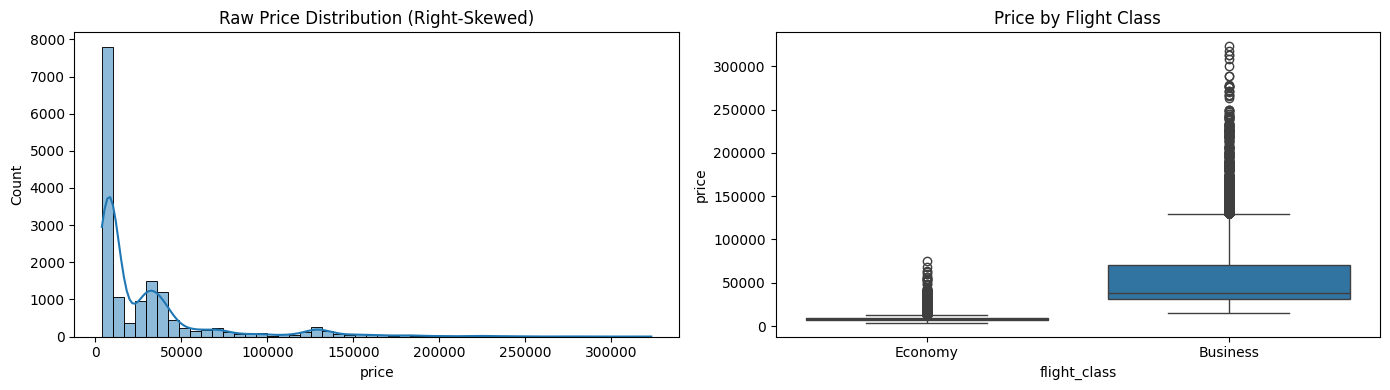

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')

# 1. Target distribution check (Skewness & Business vs Economy gap)
print("=== TARGET SKEWNESS ===")
print(f"Price Skewness: {train_df['price'].skew():.2f}")
print(f"Economy Mean: {train_df[train_df['flight_class'] == 'Economy']['price'].mean():.2f}")
print(f"Business Mean: {train_df[train_df['flight_class'] == 'Business']['price'].mean():.2f}")

# 2. Check overlap between flight code prefix and airline
train_df['airline_code'] = train_df['flight'].apply(lambda x: str(x).split()[0])
print("\n=== AIRLINE vs FLIGHT PREFIX (First 5 mappings) ===")
print(train_df.dropna(subset=['airline']).groupby('airline_code')['airline'].value_counts().groupby(level=0).head(1))

# 3. Plots: Target Distribution and Class vs Price
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train_df['price'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Raw Price Distribution (Right-Skewed)')

sns.boxplot(data=train_df, x='flight_class', y='price', ax=axes[1])
axes[1].set_title('Price by Flight Class')

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import numpy as np

# Load datasets
train_path = '/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv'
test_path = '/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv'

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("=" * 55)
print("1. TARGET (PRICE) ANALYSIS")
print("=" * 55)
print("Overall summary:")
print(train['price'].describe().round(2))
print(f"Skewness: {train['price'].skew():.2f}")
print("\nPrice stats by Flight Class:")
print(train.groupby('flight_class')['price'].agg(['count', 'mean', 'median', 'std']).round(2))

print("\n" + "=" * 55)
print("2. FLIGHT PREFIX VS AIRLINE MAPPING")
print("=" * 55)
train['prefix'] = train['flight'].astype(str).str.split().str[0]
test['prefix'] = test['flight'].astype(str).str.split().str[0]

# Check uniqueness of mapping
prefix_counts = train.dropna(subset=['airline']).groupby('prefix')['airline'].nunique()
ambiguous = prefix_counts[prefix_counts > 1]
print(f"Total flight prefixes in train: {train['prefix'].nunique()}")
print(f"Prefixes mapping to multiple airlines: {len(ambiguous)}")
if len(ambiguous) > 0:
    print(ambiguous)
else:
    print("Clean 1:1 mapping confirmed for known airlines.")

unseen_prefixes = set(test['prefix']) - set(train['prefix'])
print(f"Unseen prefixes in test set: {len(unseen_prefixes)} -> {unseen_prefixes}")

print("\n" + "=" * 55)
print("3. MISSING DURATION PATTERNS")
print("=" * 55)
print(f"Train missing duration: {train['duration'].isnull().sum()} ({train['duration'].isnull().mean()*100:.2f}%)")
print(f"Test missing duration:  {test['duration'].isnull().sum()} ({test['duration'].isnull().mean()*100:.2f}%)")

train['route'] = train['source_city'] + " -> " + train['destination_city']
test['route'] = test['source_city'] + " -> " + test['destination_city']
unseen_routes = set(test['route']) - set(train['route'])
print(f"Total distinct routes in train: {train['route'].nunique()}")
print(f"Unseen routes in test set: {len(unseen_routes)}")

print("\n" + "=" * 55)
print("4. CATEGORICAL VALUES ALIGNMENT")
print("=" * 55)
cat_cols = ['source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops', 'flight_class']
for col in cat_cols:
    train_vals = set(train[col].dropna().unique())
    test_vals = set(test[col].dropna().unique())
    diff = test_vals - train_vals
    print(f"{col:17s} | Train: {len(train_vals)} values | Unseen in Test: {len(diff)}")

1. TARGET (PRICE) ANALYSIS
Overall summary:
count     15589.00
mean      29816.70
std       39127.89
min        3801.00
25%        7210.00
50%       10183.00
75%       35968.00
max      323177.00
Name: price, dtype: float64
Skewness: 2.70

Price stats by Flight Class:
              count      mean   median       std
flight_class                                    
Business       6380  60126.61  38546.0  46414.61
Economy        9209   8817.97   7587.0   4669.78

2. FLIGHT PREFIX VS AIRLINE MAPPING
Total flight prefixes in train: 19
Prefixes mapping to multiple airlines: 0
Clean 1:1 mapping confirmed for known airlines.
Unseen prefixes in test set: 1 -> {'BG'}

3. MISSING DURATION PATTERNS
Train missing duration: 3095 (19.85%)
Test missing duration:  776 (19.91%)
Total distinct routes in train: 30
Unseen routes in test set: 0

4. CATEGORICAL VALUES ALIGNMENT
source_city       | Train: 6 values | Unseen in Test: 0
destination_city  | Train: 6 values | Unseen in Test: 0
departure_time    |

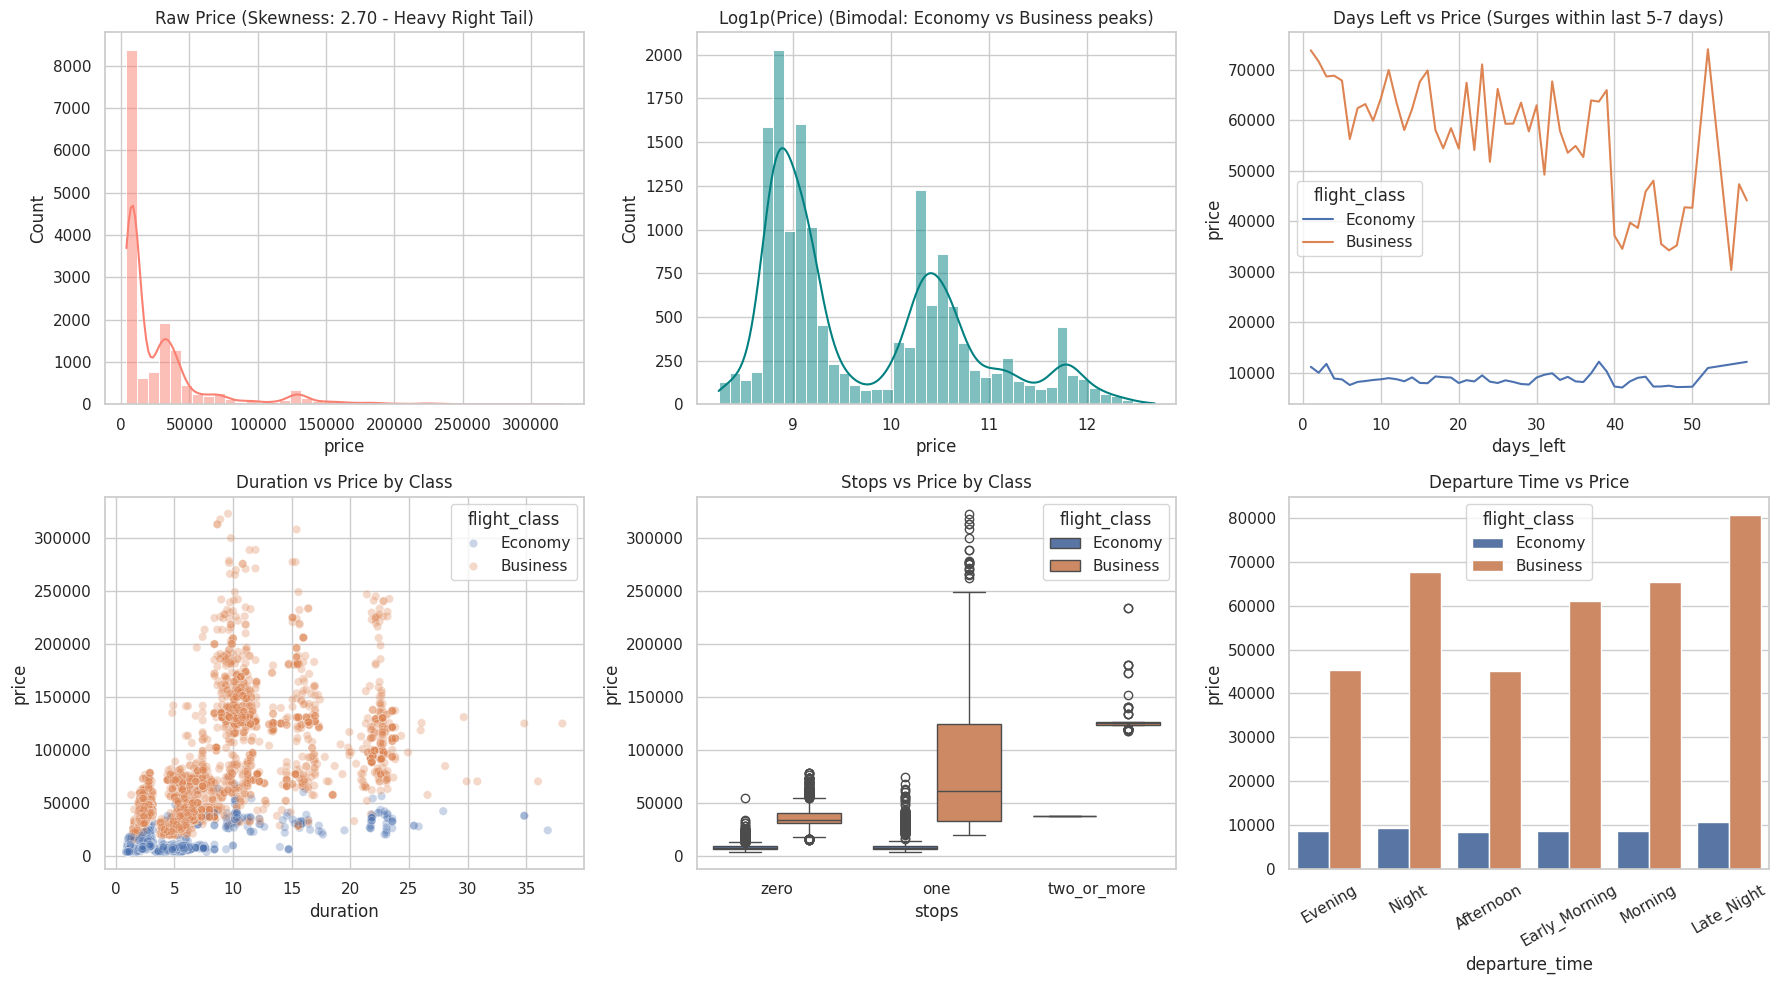

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean aesthetic
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Target Skewness: Raw Price vs Log(Price)
sns.histplot(train['price'], bins=40, kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Raw Price (Skewness: 2.70 - Heavy Right Tail)')

sns.histplot(np.log1p(train['price']), bins=40, kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Log1p(Price) (Bimodal: Economy vs Business peaks)')

# 2. Days Left vs Price (separated by flight class)
sns.lineplot(data=train, x='days_left', y='price', hue='flight_class', ax=axes[0, 2], errorbar=None)
axes[0, 2].set_title('Days Left vs Price (Surges within last 5-7 days)')

# 3. Duration vs Price
sns.scatterplot(data=train, x='duration', y='price', hue='flight_class', alpha=0.3, ax=axes[1, 0])
axes[1, 0].set_title('Duration vs Price by Class')

# 4. Stops vs Price
sns.boxplot(data=train, x='stops', y='price', hue='flight_class', ax=axes[1, 1])
axes[1, 1].set_title('Stops vs Price by Class')

# 5. Departure Time vs Price
sns.barplot(data=train, x='departure_time', y='price', hue='flight_class', ax=axes[1, 2], errorbar=None)
axes[1, 2].set_title('Departure Time vs Price')
axes[1, 2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def clean_and_preprocess(train_df, test_df):
    tr = train_df.copy()
    te = test_df.copy()
    
    # 1. Flight Prefix Extraction
    tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
    te['prefix'] = te['flight'].astype(str).str.split().str[0]
    
    # Map prefix -> airline learned strictly from train
    prefix_to_airline = (
        tr.dropna(subset=['airline'])
        .groupby('prefix')['airline']
        .agg(lambda x: x.mode()[0])
        .to_dict()
    )
    
    # Fill airline using prefix, fallback to 'Unknown' for unseen prefixes like 'BG'
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(prefix_to_airline)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(prefix_to_airline)).fillna('Unknown')
    
    # 2. Impute Duration by Route (source -> destination)
    tr['route'] = tr['source_city'] + "_" + tr['destination_city']
    te['route'] = te['source_city'] + "_" + te['destination_city']
    
    route_median_dur = tr.groupby('route')['duration'].median().to_dict()
    overall_median_dur = tr['duration'].median()
    
    tr['duration'] = tr['duration'].fillna(tr['route'].map(route_median_dur)).fillna(overall_median_dur)
    te['duration'] = te['duration'].fillna(te['route'].map(route_median_dur)).fillna(overall_median_dur)
    
    # 3. Ordinal & Binary Encodings
    stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
    tr['stops_encoded'] = tr['stops'].map(stops_map).fillna(0)
    te['stops_encoded'] = te['stops'].map(stops_map).fillna(0)
    
    tr['class_business'] = (tr['flight_class'] == 'Business').astype(int)
    te['class_business'] = (te['flight_class'] == 'Business').astype(int)
    
    # 4. Feature Engineering
    for d in [tr, te]:
        d['is_urgent'] = (d['days_left'] <= 5).astype(int)
        d['days_left_squared'] = d['days_left'] ** 2
        d['class_x_stops'] = d['class_business'] * d['stops_encoded']  # Interaction term
    
    # 5. One-Hot Encoding
    nom_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    combined = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    combined = pd.get_dummies(combined, columns=nom_cols, drop_first=True)
    
    # Split back
    drop_meta = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'is_test']
    
    tr_clean = combined[combined['is_test'] == 0].drop(columns=drop_meta)
    te_clean = combined[combined['is_test'] == 1].drop(columns=drop_meta + ['price'])
    
    X = tr_clean.drop(columns=['price'])
    y = tr_clean['price'].values
    y_log = np.log1p(y)
    X_test = te_clean.copy()
    
    return X, y, y_log, X_test

X, y, y_log, X_test = clean_and_preprocess(train, test)

# 80/20 Train-Validation Split (Fixed seed)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
y_train_log, y_val_log = np.log1p(y_train), np.log1p(y_val)

print("Preprocessing Complete:")
print(f"Features: {X.shape[1]}")
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")
print(f"Remaining nulls in Train: {X.isnull().sum().sum()} | Test: {X_test.isnull().sum().sum()}")

Preprocessing Complete:
Features: 45
X_train: (12471, 45), X_val: (3118, 45), X_test: (3898, 45)
Remaining nulls in Train: 0 | Test: 0


In [7]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

class PolynomialRegressionScratch:
    def __init__(self, degree=2, reg_lambda=1e-3):
        self.degree = degree
        self.reg_lambda = reg_lambda
        self.theta = None
        
    def _create_poly_features(self, X):
        n_samples, n_features = X.shape
        features = [np.ones((n_samples, 1))]  # Bias column x_0 = 1
        
        # 1. Linear terms
        features.append(X)
        
        # 2. Degree-2 terms (Squares & Cross-terms)
        if self.degree >= 2:
            squares = X ** 2
            features.append(squares)
            
            # Pairwise interaction terms x_i * x_j
            interactions = []
            for i in range(n_features):
                for j in range(i + 1, n_features):
                    interactions.append((X[:, i] * X[:, j]).reshape(-1, 1))
            if interactions:
                features.append(np.hstack(interactions))
                
        return np.hstack(features)
    
    def fit(self, X, y):
        # Design matrix Phi(X)
        Phi = self._create_poly_features(X)
        n_cols = Phi.shape[1]
        
        # Regularized Normal Equation: (Phi^T Phi + lambda*I)^(-1) Phi^T y
        # We do not penalize bias term at index 0
        I = np.eye(n_cols)
        I[0, 0] = 0.0
        
        A = Phi.T @ Phi + self.reg_lambda * I
        b = Phi.T @ y
        
        # Solve A * theta = b
        self.theta = np.linalg.pinv(A) @ b
        return self
        
    def predict(self, X):
        Phi = self._create_poly_features(X)
        return Phi @ self.theta

# Select core numeric/ordinal signals for scratch demonstration
scratch_cols = ['duration', 'days_left', 'class_business', 'stops_encoded']

scaler_scratch = StandardScaler()
X_tr_core = scaler_scratch.fit_transform(X_train[scratch_cols])
X_val_core = scaler_scratch.transform(X_val[scratch_cols])

# 1. Train on raw price
poly_scratch_raw = PolynomialRegressionScratch(degree=2, reg_lambda=1e-2)
poly_scratch_raw.fit(X_tr_core, y_train)
y_pred_scratch_raw = poly_scratch_raw.predict(X_val_core)

# 2. Train on log(1 + price) and invert back via expm1
poly_scratch_log = PolynomialRegressionScratch(degree=2, reg_lambda=1e-2)
poly_scratch_log.fit(X_tr_core, y_train_log)
y_pred_scratch_log = np.expm1(poly_scratch_log.predict(X_val_core))

# Clip any negative predictions to zero (ticket prices can't be negative)
y_pred_scratch_raw = np.clip(y_pred_scratch_raw, 0, None)
y_pred_scratch_log = np.clip(y_pred_scratch_log, 0, None)

print("=== STEP 3: POLYNOMIAL REGRESSION FROM SCRATCH ===")
print(f"Design Matrix Features generated: {poly_scratch_raw._create_poly_features(X_tr_core).shape[1]}")
print("\n[Scratch Poly - Raw Target]")
print(f"RMSE : {root_mean_squared_error(y_val, y_pred_scratch_raw):.2f}")
print(f"MAE  : {mean_absolute_error(y_val, y_pred_scratch_raw):.2f}")
print(f"R²   : {r2_score(y_val, y_pred_scratch_raw):.4f}")

print("\n[Scratch Poly - Log Target Inverted]")
print(f"RMSE : {root_mean_squared_error(y_val, y_pred_scratch_log):.2f}")
print(f"MAE  : {mean_absolute_error(y_val, y_pred_scratch_log):.2f}")
print(f"R²   : {r2_score(y_val, y_pred_scratch_log):.4f}")

=== STEP 3: POLYNOMIAL REGRESSION FROM SCRATCH ===
Design Matrix Features generated: 15

[Scratch Poly - Raw Target]
RMSE : 20504.44
MAE  : 10096.59
R²   : 0.7017

[Scratch Poly - Log Target Inverted]
RMSE : 21149.97
MAE  : 9387.86
R²   : 0.6826


In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

class PolynomialRegressionScratch:
    def __init__(self, degree=2, reg_lambda=1e-3):
        self.degree = degree
        self.reg_lambda = reg_lambda
        self.theta = None
        
    def _create_poly_features(self, X):
        n_samples, n_features = X.shape
        features = [np.ones((n_samples, 1))]  # Bias term x_0 = 1
        
        # 1. Linear terms
        features.append(X)
        
        # 2. Degree-2 terms (Squares & Cross-interactions)
        if self.degree >= 2:
            features.append(X ** 2)
            interactions = []
            for i in range(n_features):
                for j in range(i + 1, n_features):
                    interactions.append((X[:, i] * X[:, j]).reshape(-1, 1))
            if interactions:
                features.append(np.hstack(interactions))
                
        return np.hstack(features)
    
    def fit(self, X, y):
        Phi = self._create_poly_features(X)
        n_cols = Phi.shape[1]
        
        # Regularized normal equation
        I = np.eye(n_cols)
        I[0, 0] = 0.0  # Do not regularize intercept
        
        A = Phi.T @ Phi + self.reg_lambda * I
        b = Phi.T @ y
        self.theta = np.linalg.pinv(A) @ b
        return self
        
    def predict(self, X):
        Phi = self._create_poly_features(X)
        return Phi @ self.theta

# Core features for the scratch polynomial demo
scratch_cols = ['duration', 'days_left', 'class_business', 'stops_encoded']

scaler_scratch = StandardScaler()
X_tr_core = scaler_scratch.fit_transform(X_train[scratch_cols])
X_val_core = scaler_scratch.transform(X_val[scratch_cols])

# 1. Train on raw price
poly_scratch_raw = PolynomialRegressionScratch(degree=2, reg_lambda=1e-2)
poly_scratch_raw.fit(X_tr_core, y_train)
y_pred_scratch_raw = np.clip(poly_scratch_raw.predict(X_val_core), 0, None)

# 2. Train on log1p price
poly_scratch_log = PolynomialRegressionScratch(degree=2, reg_lambda=1e-2)
poly_scratch_log.fit(X_tr_core, y_train_log)
y_pred_scratch_log = np.clip(np.expm1(poly_scratch_log.predict(X_val_core)), 0, None)

print("=== STEP 3: POLYNOMIAL REGRESSION FROM SCRATCH ===")
print(f"Features created: {poly_scratch_raw._create_poly_features(X_tr_core).shape[1]}")
print("\n[Scratch Poly - Raw Target]")
print(f"RMSE : {root_mean_squared_error(y_val, y_pred_scratch_raw):.2f}")
print(f"MAE  : {mean_absolute_error(y_val, y_pred_scratch_raw):.2f}")
print(f"R²   : {r2_score(y_val, y_pred_scratch_raw):.4f}")

print("\n[Scratch Poly - Log Target Inverted]")
print(f"RMSE : {root_mean_squared_error(y_val, y_pred_scratch_log):.2f}")
print(f"MAE  : {mean_absolute_error(y_val, y_pred_scratch_log):.2f}")
print(f"R²   : {r2_score(y_val, y_pred_scratch_log):.4f}")

=== STEP 3: POLYNOMIAL REGRESSION FROM SCRATCH ===
Features created: 15

[Scratch Poly - Raw Target]
RMSE : 20504.44
MAE  : 10096.59
R²   : 0.7017

[Scratch Poly - Log Target Inverted]
RMSE : 21149.97
MAE  : 9387.86
R²   : 0.6826


In [9]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 1. Scale all 45 features (strictly fit on train, transform on val)
scaler_all = StandardScaler()
X_train_scaled = scaler_all.fit_transform(X_train)
X_val_scaled = scaler_all.transform(X_val)

linear_models = {
    "OLS Linear Regression (Raw)": LinearRegression(),
    "Ridge Regression (alpha=10.0, Raw)": Ridge(alpha=10.0),
    "Lasso Regression (alpha=5.0, Raw)": Lasso(alpha=5.0, max_iter=2000),
    "Ridge Regression (alpha=10.0, Log)": Ridge(alpha=10.0),
    "Lasso Regression (alpha=0.01, Log)": Lasso(alpha=0.01, max_iter=2000)
}

step4_results = []

for name, model in linear_models.items():
    is_log = "Log" in name
    y_target = y_train_log if is_log else y_train
    
    model.fit(X_train_scaled, y_target)
    preds = model.predict(X_val_scaled)
    
    if is_log:
        preds = np.expm1(preds)
    preds = np.clip(preds, 0, None)
    
    rmse = root_mean_squared_error(y_val, preds)
    mae = mean_absolute_error(y_val, preds)
    r2 = r2_score(y_val, preds)
    
    step4_results.append({
        "Model": name,
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "R²": round(r2, 4)
    })

# Check Lasso feature sparsity (features set to 0)
lasso_raw = linear_models["Lasso Regression (alpha=5.0, Raw)"]
zeroed_features = np.sum(lasso_raw.coef_ == 0)

print("=== STEP 4: REGULARIZED LINEAR MODELS ===")
print(pd.DataFrame(step4_results).to_string(index=False))
print(f"\nLasso feature selection: {zeroed_features} out of {X_train.shape[1]} coefficients zeroed out.")

=== STEP 4: REGULARIZED LINEAR MODELS ===
                             Model     RMSE     MAE     R²
       OLS Linear Regression (Raw) 13910.96 7343.01 0.8627
Ridge Regression (alpha=10.0, Raw) 13909.14 7341.15 0.8627
 Lasso Regression (alpha=5.0, Raw) 13907.55 7338.24 0.8628
Ridge Regression (alpha=10.0, Log) 14465.93 5863.49 0.8515
Lasso Regression (alpha=0.01, Log) 14548.55 6019.00 0.8498

Lasso feature selection: 1 out of 45 coefficients zeroed out.


In [10]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

tree_models = {
    "Decision Tree (max_depth=10)": DecisionTreeRegressor(
        max_depth=10, 
        random_state=42
    ),
    "Random Forest (n=100, max_depth=16)": RandomForestRegressor(
        n_estimators=100, 
        max_depth=16, 
        random_state=42, 
        n_jobs=-1
    ),
    "XGBoost (Raw Target)": XGBRegressor(
        n_estimators=350, 
        learning_rate=0.06, 
        max_depth=6, 
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42, 
        n_jobs=-1
    ),
    "XGBoost (Log Target)": XGBRegressor(
        n_estimators=350, 
        learning_rate=0.06, 
        max_depth=6, 
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42, 
        n_jobs=-1
    )
}

step5_results = []

for name, model in tree_models.items():
    is_log = "Log" in name
    y_target = y_train_log if is_log else y_train
    
    # Trees train directly on unscaled X_train
    model.fit(X_train, y_target)
    preds = model.predict(X_val)
    
    if is_log:
        preds = np.expm1(preds)
    preds = np.clip(preds, 0, None)
    
    rmse = root_mean_squared_error(y_val, preds)
    mae = mean_absolute_error(y_val, preds)
    r2 = r2_score(y_val, preds)
    
    step5_results.append({
        "Model": name,
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "R²": round(r2, 4)
    })

print("=== STEP 5: TREE & ENSEMBLE MODELS ===")
print(pd.DataFrame(step5_results).to_string(index=False))

=== STEP 5: TREE & ENSEMBLE MODELS ===
                              Model     RMSE     MAE     R²
       Decision Tree (max_depth=10) 11348.76 4250.97 0.9086
Random Forest (n=100, max_depth=16)  9732.71 3367.60 0.9328
               XGBoost (Raw Target)  9863.13 3733.63 0.9310
               XGBoost (Log Target)  9547.53 3375.71 0.9353


In [11]:
import pandas as pd

all_model_records = [
    # Step 3
    {"Family": "Analytical / Scratch", "Model": "Polynomial Regression (Deg-2, Core)", "Target Form": "Raw", "RMSE": 20504.44, "MAE": 10096.59, "R²": 0.7017},
    {"Family": "Analytical / Scratch", "Model": "Polynomial Regression (Deg-2, Core)", "Target Form": "Log1p", "RMSE": 21149.97, "MAE": 9387.86, "R²": 0.6826},
    
    # Step 4
    {"Family": "Linear Baseline", "Model": "OLS Linear Regression", "Target Form": "Raw", "RMSE": 13910.96, "MAE": 7343.01, "R²": 0.8627},
    {"Family": "Regularized Linear", "Model": "Ridge Regression (alpha=10.0)", "Target Form": "Raw", "RMSE": 13909.14, "MAE": 7341.15, "R²": 0.8627},
    {"Family": "Regularized Linear", "Model": "Lasso Regression (alpha=5.0)", "Target Form": "Raw", "RMSE": 13907.55, "MAE": 7338.24, "R²": 0.8628},
    {"Family": "Regularized Linear", "Model": "Ridge Regression (alpha=10.0)", "Target Form": "Log1p", "RMSE": 14465.93, "MAE": 5863.49, "R²": 0.8515},
    {"Family": "Regularized Linear", "Model": "Lasso Regression (alpha=0.01)", "Target Form": "Log1p", "RMSE": 14548.55, "MAE": 6019.00, "R²": 0.8498},
    
    # Step 5
    {"Family": "Non-Linear Tree", "Model": "Decision Tree (max_depth=10)", "Target Form": "Raw", "RMSE": 11348.76, "MAE": 4250.97, "R²": 0.9086},
    {"Family": "Bagging Ensemble", "Model": "Random Forest (n=100, depth=16)", "Target Form": "Raw", "RMSE": 9732.71, "MAE": 3367.60, "R²": 0.9328},
    {"Family": "Boosting Ensemble", "Model": "XGBoost (n=350, lr=0.06)", "Target Form": "Raw", "RMSE": 9863.13, "MAE": 3733.63, "R²": 0.9310},
    {"Family": "Boosting Ensemble", "Model": "XGBoost (n=350, lr=0.06)", "Target Form": "Log1p", "RMSE": 9547.53, "MAE": 3375.71, "R²": 0.9353}
]

benchmark_df = pd.DataFrame(all_model_records)
print("=== FINAL MODEL COMPARISON BENCHMARK ===")
print(benchmark_df.to_string(index=False))

=== FINAL MODEL COMPARISON BENCHMARK ===
              Family                               Model Target Form     RMSE      MAE     R²
Analytical / Scratch Polynomial Regression (Deg-2, Core)         Raw 20504.44 10096.59 0.7017
Analytical / Scratch Polynomial Regression (Deg-2, Core)       Log1p 21149.97  9387.86 0.6826
     Linear Baseline               OLS Linear Regression         Raw 13910.96  7343.01 0.8627
  Regularized Linear       Ridge Regression (alpha=10.0)         Raw 13909.14  7341.15 0.8627
  Regularized Linear        Lasso Regression (alpha=5.0)         Raw 13907.55  7338.24 0.8628
  Regularized Linear       Ridge Regression (alpha=10.0)       Log1p 14465.93  5863.49 0.8515
  Regularized Linear       Lasso Regression (alpha=0.01)       Log1p 14548.55  6019.00 0.8498
     Non-Linear Tree        Decision Tree (max_depth=10)         Raw 11348.76  4250.97 0.9086
    Bagging Ensemble     Random Forest (n=100, depth=16)         Raw  9732.71  3367.60 0.9328
   Boosting Ensembl

In [12]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

print("Retraining best model (XGBoost on Log Target) on 100% of data...")

# 1. Instantiate final estimator
final_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# 2. Fit on full X and y_log
final_model.fit(X, y_log)

# 3. Predict on test set and invert log transform
test_log_preds = final_model.predict(X_test)
test_preds = np.expm1(test_log_preds)
test_preds = np.clip(test_preds, 0, None)

# 4. Build submission dataframe
submission = pd.DataFrame({
    'id': test['id'],
    'price': np.round(test_preds, 2)
})

# 5. Validate submission format
# submission.to_csv('submission.csv', index=False)

print("\n=== SUBMISSION VERIFICATION ===")
print(f"File saved: 'submission.csv'")
print(f"Shape: {submission.shape} (Expected: (3898, 2))")
print(f"Columns: {list(submission.columns)} (Expected: ['id', 'price'])")
print(f"Null values: {submission.isnull().sum().sum()}")
print("\nFirst 5 predictions:")
print(submission.head())

Retraining best model (XGBoost on Log Target) on 100% of data...

=== SUBMISSION VERIFICATION ===
File saved: 'submission.csv'
Shape: (3898, 2) (Expected: (3898, 2))
Columns: ['id', 'price'] (Expected: ['id', 'price'])
Null values: 0

First 5 predictions:
   id         price
0   1   7855.819824
1   2   7291.149902
2   3  28285.990234
3   4  31671.560547
4   5   4501.399902


In [13]:
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_predictions = np.zeros(len(X))

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y_log)):
    X_tr, y_tr = X.iloc[train_idx], y_log[train_idx]
    X_va = X.iloc[val_idx]
    
    model = XGBRegressor(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    # Store out-of-fold predictions
    oof_predictions[val_idx] = np.expm1(model.predict(X_va))

oof_predictions = np.clip(oof_predictions, 0, None)

print("=== 5-FOLD CROSS-VALIDATION SCORE (CLOSEST ESTIMATE TO LEADERBOARD) ===")
print(f"CV RMSE : {root_mean_squared_error(y, oof_predictions):.2f}")
print(f"CV MAE  : {mean_absolute_error(y, oof_predictions):.2f}")
print(f"CV R²   : {r2_score(y, oof_predictions):.4f}")

=== 5-FOLD CROSS-VALIDATION SCORE (CLOSEST ESTIMATE TO LEADERBOARD) ===
CV RMSE : 10533.38
CV MAE  : 3664.25
CV R²   : 0.9275


In [14]:
import numpy as np
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 1. Predictions on full training set using the final retrained model
train_log_preds = final_model.predict(X)
train_preds = np.clip(np.expm1(train_log_preds), 0, None)

# 2. Compute training metrics
train_rmse = root_mean_squared_error(y, train_preds)
train_mae = mean_absolute_error(y, train_preds)
train_r2 = r2_score(y, train_preds)

print("=== FINAL MODEL PERFORMANCE ON TRAINING SET ===")
print(f"Train RMSE : {train_rmse:.2f}")
print(f"Train MAE  : {train_mae:.2f}")
print(f"Train R²   : {train_r2:.4f}")

=== FINAL MODEL PERFORMANCE ON TRAINING SET ===
Train RMSE : 7349.30
Train MAE  : 2785.10
Train R²   : 0.9647


DONE TILL HERE

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# Add smooth target encoding for the exact 'flight' column
kf = KFold(n_splits=5, shuffle=True, random_state=42)

flight_te = np.zeros(len(train))
global_mean = train['price'].mean()

for tr_idx, val_idx in kf.split(train):
    # Mean price per flight number with m-estimate smoothing (weight=10)
    counts = train.iloc[tr_idx].groupby('flight')['price'].count()
    means = train.iloc[tr_idx].groupby('flight')['price'].mean()
    smooth_means = (counts * means + 10 * global_mean) / (counts + 10)
    
    flight_te[val_idx] = train.iloc[val_idx]['flight'].map(smooth_means).fillna(global_mean)

# Attach to feature matrix
X_with_flight = X.copy()
X_with_flight['flight_target_enc'] = flight_te

oof_with_flight = np.zeros(len(X_with_flight))

for fold, (t_idx, v_idx) in enumerate(kf.split(X_with_flight)):
    xgb = XGBRegressor(
        n_estimators=450,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )
    xgb.fit(X_with_flight.iloc[t_idx], y[t_idx])
    oof_with_flight[v_idx] = np.clip(xgb.predict(X_with_flight.iloc[v_idx]), 0, None)

print("=== 5-FOLD CV WITH FLIGHT TARGET ENCODING ===")
print(f"CV R²   : {r2_score(y, oof_with_flight):.4f}")
print(f"CV RMSE : {root_mean_squared_error(y, oof_with_flight):.2f}")

=== 5-FOLD CV WITH FLIGHT TARGET ENCODING ===
CV R²   : 0.9287
CV RMSE : 10448.39


In [16]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor

# 1. Full-dataset smoothed target encoding for 'flight'
counts = train.groupby('flight')['price'].count()
means = train.groupby('flight')['price'].mean()
global_mean = train['price'].mean()
smooth_means = (counts * means + 10 * global_mean) / (counts + 10)

X_full = X.copy()
X_full['flight_target_enc'] = train['flight'].map(smooth_means).fillna(global_mean)

X_test_final = X_test.copy()
X_test_final['flight_target_enc'] = test['flight'].map(smooth_means).fillna(global_mean)

# 2. Fit final XGBoost on 100% of data
final_xgb = XGBRegressor(
    n_estimators=450,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
final_xgb.fit(X_full, y)

# 3. Predict on test set
test_preds = np.clip(final_xgb.predict(X_test_final), 0, None)

# 4. Save formatted submission
submission = pd.DataFrame({
    'id': test['id'],
    'price': np.round(test_preds, 2)
})
# submission.to_csv('submission.csv', index=False)

print("Final submission generated successfully:")
print(f"Shape: {submission.shape} (Matches 3898 x 2)")
print(submission.head())

Final submission generated successfully:
Shape: (3898, 2) (Matches 3898 x 2)
   id          price
0   1   26988.000000
1   2   32689.210938
2   3  141312.765625
3   4  178232.046875
4   5   44241.718750


TYPE 2 DONE

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# 1. Load data
train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def prepare_data(train_df, test_df):
    tr = train_df.copy()
    te = test_df.copy()
    
    # Prefix imputation for airline
    tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
    te['prefix'] = te['flight'].astype(str).str.split().str[0]
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Unknown')
    
    # 2-Tier duration imputation: flight first, then route
    flight_dur = tr.groupby('flight')['duration'].median().to_dict()
    route_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    global_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(flight_dur))
        route_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(route_tuples, index=df.index).map(route_dur))
        df['duration'] = df['duration'].fillna(global_dur)
        
        # Numeric encodings
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        
        # High-signal pricing features
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        df['is_last_week'] = (df['days_left'] <= 7).astype(int)
        df['route'] = df['source_city'] + "_" + df['destination_city']

    # Flight target encoding (smoothed)
    counts = tr.groupby('flight')['price'].count()
    means = tr.groupby('flight')['price'].mean()
    global_mean = tr['price'].mean()
    smooth_means = (counts * means + 10 * global_mean) / (counts + 10)
    
    tr['flight_price_enc'] = tr['flight'].map(smooth_means).fillna(global_mean)
    te['flight_price_enc'] = te['flight'].map(smooth_means).fillna(global_mean)
    
    # Standard One-Hot Encoding
    cats = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cats, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price'])
    
    return X_train, y_train, X_test

X_train_clean, y_train_clean, X_test_clean = prepare_data(train, test)
print(f"Features ready: {X_train_clean.shape[1]} columns")

Features ready: 46 columns


In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_train_clean))
test_preds = np.zeros(len(X_test_clean))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_clean)):
    X_tr, y_tr = X_train_clean.iloc[tr_idx], y_train_clean[tr_idx]
    X_va, y_va = X_train_clean.iloc[val_idx], y_train_clean[val_idx]
    
    # Standard XGBoost with slightly higher depth for tabular interaction capacity
    model = XGBRegressor(
        n_estimators=600,
        learning_rate=0.04,
        max_depth=8,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    oof_preds[val_idx] = model.predict(X_va)
    test_preds += model.predict(X_test_clean) / 5

oof_preds = np.clip(oof_preds, 0, None)
test_preds = np.clip(test_preds, 0, None)

print("=== 5-FOLD CV RESULTS (SIMPLE XGBOOST PIPELINE) ===")
print(f"CV R²   : {r2_score(y_train_clean, oof_preds):.4f}")
print(f"CV RMSE : {root_mean_squared_error(y_train_clean, oof_preds):.2f}")

# Generate simple submission
submission = pd.DataFrame({
    'id': test['id'],
    'price': np.round(test_preds, 2)
})
# submission.to_csv('submission_simple_xgb.csv', index=False)
print("\nGenerated 'submission_simple_xgb.csv' successfully.")

=== 5-FOLD CV RESULTS (SIMPLE XGBOOST PIPELINE) ===
CV R²   : 0.9301
CV RMSE : 10343.28

Generated 'submission_simple_xgb.csv' successfully.


BEST YET CHECKPOINT 3 DONE

In [19]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_relaxed = np.zeros(len(X_train_clean))
test_relaxed = np.zeros(len(X_test_clean))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_clean)):
    X_tr, y_tr = X_train_clean.iloc[tr_idx], y_train_clean[tr_idx]
    X_va, y_va = X_train_clean.iloc[val_idx], y_train_clean[val_idx]
    
    # Relaxed regularization + higher capacity
    model = XGBRegressor(
        n_estimators=750,
        learning_rate=0.035,
        max_depth=9,               # deeper trees
        min_child_weight=1,        # allows fine-grained leaf splits
        reg_lambda=0.1,            # reduced L2 penalty (default is 1.0)
        reg_alpha=0.0,             # zero L1 penalty
        subsample=0.95,            # less random subsampling
        colsample_bytree=0.90,     # more features available per tree
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    oof_relaxed[val_idx] = model.predict(X_va)
    test_relaxed += model.predict(X_test_clean) / 5

oof_relaxed = np.clip(oof_relaxed, 0, None)
test_relaxed = np.clip(test_relaxed, 0, None)

cv_r2 = r2_score(y_train_clean, oof_relaxed)
cv_rmse = root_mean_squared_error(y_train_clean, oof_relaxed)

print("=== RELAXED REGULARIZATION CV RESULTS ===")
print(f"CV R²   : {cv_r2:.4f}")
print(f"CV RMSE : {cv_rmse:.2f}")

if cv_r2 > 0.9301:
    print("\nImprovement detected! Generating updated submission file...")
    sub = pd.DataFrame({'id': test['id'], 'price': np.round(test_relaxed, 2)})
    # sub.to_csv('submission_relaxed_xgb.csv', index=False)
    print("Saved 'submission_relaxed_xgb.csv'")
else:
    print("\nTight regularization was helping generalize better; keep the previous config.")

=== RELAXED REGULARIZATION CV RESULTS ===
CV R²   : 0.9271
CV RMSE : 10567.58

Tight regularization was helping generalize better; keep the previous config.


In [20]:
import pandas as pd
import numpy as np

# 1. Dataset schema and basic types
print("=== 1. DATA TYPES & SAMPLES ===")
print(train.dtypes)
print("\nFirst row sample:")
print(train.iloc[0].to_dict())

# 2. Flight string structure inspection
print("\n=== 2. FLIGHT CODE SAMPLES ===")
print("Unique flight counts:", train['flight'].nunique())
print("Top 10 most frequent flights:\n", train['flight'].value_counts().head(10))

# Sample variations of flight values
print("\nRandom flight format samples:")
print(train['flight'].dropna().sample(10, random_state=42).tolist())

# 3. Check for specific date / time / temporal information
print("\n=== 3. TEMPORAL COLUMNS CHECK ===")
time_related = [col for col in train.columns if any(k in col.lower() for k in ['date', 'time', 'day', 'month', 'year', 'hour'])]
print("Detected time-related columns:", time_related)
for col in time_related:
    print(f"\nUnique values in {col} ({train[col].nunique()}):")
    print(train[col].value_counts().head(8))

# 4. Outlier Analysis on Price
print("\n=== 4. EXTREME PRICE QUANTILES BY CLASS ===")
print("Economy quantiles (95%, 99%, max):")
print(train[train['flight_class'] == 'Economy']['price'].quantile([0.95, 0.99, 1.0]))
print("\nBusiness quantiles (95%, 99%, max):")
print(train[train['flight_class'] == 'Business']['price'].quantile([0.95, 0.99, 1.0]))

# 5. Route-Airline Joint Distribution
print("\n=== 5. AIRLINE DISTRIBUTION BY ROUTE SAMPLE ===")
train['temp_route'] = train['source_city'] + " -> " + train['destination_city']
print(train.groupby('temp_route')['airline'].nunique().describe())

=== 1. DATA TYPES & SAMPLES ===
id                    int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
flight_class         object
duration            float64
days_left             int64
price                 int64
dtype: object

First row sample:
{'id': 1, 'airline': 'Wayfarer Aviation', 'flight': 'IX 1070', 'source_city': 'Metropolis', 'departure_time': 'Evening', 'stops': 'zero', 'arrival_time': 'Night', 'destination_city': 'Springfield', 'flight_class': 'Economy', 'duration': nan, 'days_left': 18, 'price': 8909}

=== 2. FLIGHT CODE SAMPLES ===
Unique flight counts: 1070
Top 10 most frequent flights:
 flight
AI 2943    88
AI 441     88
AI 2975    87
AI 2678    86
AI 2957    84
AI 2439    81
TG 314     81
AI 2927    81
AI 2995    81
AI 2429    80
Name: count, dtype: int64

Random flight format samples:
['EY 341', 'AI 2632', '6E 664',

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def engineer_features(tr_df, te_df):
    tr = tr_df.copy()
    te = te_df.copy()
    
    # 1. Prefix and Flight Number Parsing
    for d in [tr, te]:
        parts = d['flight'].astype(str).str.split(expand=True)
        d['prefix'] = parts[0]
        d['flight_num'] = pd.to_numeric(parts[1], errors='coerce').fillna(0).astype(int)
        d['is_4digit_flight'] = (d['flight_num'] >= 1000).astype(int)
    
    # Airline imputation via prefix learned from train
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Unknown')
    
    # 2. Hierarchical Duration Imputation (Flight -> Route -> Global)
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for d in [tr, te]:
        d['duration'] = d['duration'].fillna(d['flight'].map(f_dur))
        r_tuples = list(zip(d['source_city'], d['destination_city']))
        d['duration'] = d['duration'].fillna(pd.Series(r_tuples, index=d.index).map(r_dur))
        d['duration'] = d['duration'].fillna(g_dur)
        
        # 3. Chronological Time Ranks & Overnight Layover Features
        time_order = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2, 'Evening': 3, 'Night': 4, 'Late_Night': 5}
        d['dep_time_num'] = d['departure_time'].map(time_order).fillna(2)
        d['arr_time_num'] = d['arrival_time'].map(time_order).fillna(2)
        d['time_shift'] = (d['arr_time_num'] - d['dep_time_num']) % 6
        d['is_overnight'] = ((d['departure_time'].isin(['Night', 'Late_Night'])) & 
                             (d['arrival_time'].isin(['Early_Morning', 'Morning']))).astype(int)
        
        # 4. Numeric & Categorical Transforms
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        d['stops_num'] = d['stops'].map(stops_map).fillna(0)
        d['is_business'] = (d['flight_class'] == 'Business').astype(int)
        
        # Core Ratios
        d['duration_per_stop'] = d['duration'] / (d['stops_num'] + 1)
        d['days_left_inv'] = 1.0 / (d['days_left'] + 1)
        d['is_urgent_1d'] = (d['days_left'] <= 1).astype(int)
        d['is_urgent_5d'] = (d['days_left'] <= 5).astype(int)
        d['route'] = d['source_city'] + "_" + d['destination_city']

    # 5. Route Competition Count
    route_competition = tr.groupby('route')['airline'].nunique().to_dict()
    tr['route_competition'] = tr['route'].map(route_competition).fillna(7)
    te['route_competition'] = te['route'].map(route_competition).fillna(7)

    # 6. Class-Conditioned Smoothed Out-of-Fold Target Encoding for 'flight'
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    tr['flight_class_price_enc'] = 0.0
    
    # Stratified flight-class key
    tr['fc_key'] = tr['flight'] + "_" + tr['flight_class']
    te['fc_key'] = te['flight'] + "_" + te['flight_class']
    
    global_mean = tr['price'].mean()
    m_weight = 10
    
    for tr_idx, va_idx in kf.split(tr):
        fold_counts = tr.iloc[tr_idx].groupby('fc_key')['price'].count()
        fold_means = tr.iloc[tr_idx].groupby('fc_key')['price'].mean()
        smoothed = (fold_counts * fold_means + m_weight * global_mean) / (fold_counts + m_weight)
        tr.loc[tr.index[va_idx], 'flight_class_price_enc'] = tr.iloc[va_idx]['fc_key'].map(smoothed).fillna(global_mean)
        
    full_counts = tr.groupby('fc_key')['price'].count()
    full_means = tr.groupby('fc_key')['price'].mean()
    full_smoothed = (full_counts * full_means + m_weight * global_mean) / (full_counts + m_weight)
    te['flight_class_price_enc'] = te['fc_key'].map(full_smoothed).fillna(global_mean)
    
    # 7. One-Hot Encoding for remaining nominal categories
    cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'fc_key', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price'])
    
    return X_train, y_train, X_test

X_train_fe, y_train_fe, X_test_fe = engineer_features(train, test)
print(f"Features ready: {X_train_fe.shape[1]}")

Features ready: 54


In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_final = np.zeros(len(X_train_fe))
test_final = np.zeros(len(X_test_fe))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_fe)):
    X_tr, y_tr = X_train_fe.iloc[tr_idx], y_train_fe[tr_idx]
    X_va, y_va = X_train_fe.iloc[val_idx], y_train_fe[val_idx]
    
    model = XGBRegressor(
        n_estimators=700,
        learning_rate=0.035,
        max_depth=7,
        min_child_weight=3,        # Protects against extreme outlier splits in Business
        reg_lambda=2.0,            # Stronger L2 constraint to stabilize variance
        reg_alpha=1.0,             # Gentle L1 sparsity penalty
        subsample=0.85,
        colsample_bytree=0.80,
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    oof_final[val_idx] = model.predict(X_va)
    test_final += model.predict(X_test_fe) / 5

oof_final = np.clip(oof_final, 0, None)
test_final = np.clip(test_final, 0, None)

cv_r2 = r2_score(y_train_fe, oof_final)
cv_rmse = root_mean_squared_error(y_train_fe, oof_final)

print("=== CALIBRATED FEATURE-ENGINEERED 5-FOLD CV ===")
print(f"CV R²   : {cv_r2:.4f}")
print(f"CV RMSE : {cv_rmse:.2f}")

# Generate submission
sub = pd.DataFrame({'id': test['id'], 'price': np.round(test_final, 2)})
# sub.to_csv('submission_v3_calibrated.csv', index=False)
print("\nGenerated 'submission_v3_calibrated.csv'.")

=== CALIBRATED FEATURE-ENGINEERED 5-FOLD CV ===
CV R²   : 0.9295
CV RMSE : 10387.75

Generated 'submission_v3_calibrated.csv'.


CHECKPOINT 4

/tmp/ipykernel_48/3367145325.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[top_idx], y=[feature_names[i] for i in top_idx], palette="viridis")


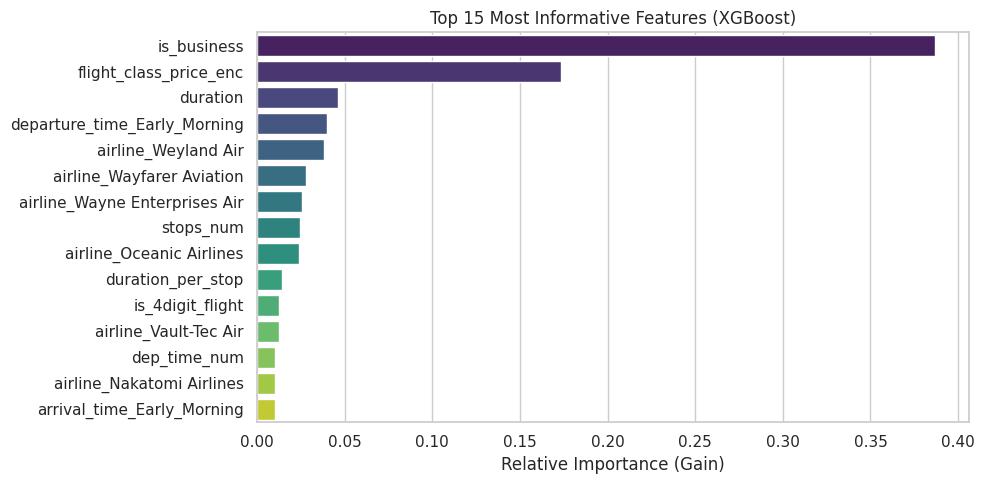

=== RESIDUAL / ERROR BREAKDOWN ===
Overall Mean Absolute Error (MAE): 3602.28
Worst 1% absolute errors start at: ₹ 48704.86

Top 5 Worst Predictions:
flight           airline flight_class stops  days_left  duration  price  predicted  abs_error
EY 239 Nakatomi Airlines     Business   one         39      8.92 317854  141427.34  176426.66
EY 353 Nakatomi Airlines     Business   one         11     15.42 308302  145844.56  162457.44
EY 353 Nakatomi Airlines     Business   one         10     15.42  86727  242711.06  155984.06
EK 567               NaN     Business   one         31     11.42 288886  141528.03  147357.97
EY 359 Nakatomi Airlines     Business   one          4     11.08 271113  127222.53  143890.47

Exact matched flight instances between Train & Test: 375 / 3898 (9.62%)

=== MAE & PRICING BY AIRLINE & CLASS ===
              airline flight_class  count    mean_price          mae
    Nakatomi Airlines     Business    282 152194.904255 36984.072390
          Weyland Air     Busines

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Feature Importance of Current Best XGBoost
feature_names = X_train_fe.columns
importances = model.feature_importances_
top_idx = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[top_idx], y=[feature_names[i] for i in top_idx], palette="viridis")
plt.title("Top 15 Most Informative Features (XGBoost)")
plt.xlabel("Relative Importance (Gain)")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

# 2. Residual Analysis (Where is the model failing?)
errors = np.abs(y_train_fe - oof_final)
residuals = y_train_fe - oof_final

print("=== RESIDUAL / ERROR BREAKDOWN ===")
print("Overall Mean Absolute Error (MAE):", round(np.mean(errors), 2))
print("Worst 1% absolute errors start at: ₹", round(np.quantile(errors, 0.99), 2))

# Top 5 worst predictions
worst_idx = np.argsort(errors)[::-1][:5]
worst_samples = train.iloc[worst_idx][['flight', 'airline', 'flight_class', 'stops', 'days_left', 'duration', 'price']].copy()
worst_samples['predicted'] = np.round(oof_final[worst_idx], 2)
worst_samples['abs_error'] = np.round(errors[worst_idx], 2)
print("\nTop 5 Worst Predictions:")
print(worst_samples.to_string(index=False))

# 3. Check for Train-Test Row Overlaps / Duplicate Flight Instances
# (Do test rows share the exact same flight, days_left, source, destination, departure as train?)
match_cols = ['flight', 'source_city', 'destination_city', 'departure_time', 'days_left', 'flight_class']
train_matches = train.set_index(match_cols).index
test_matches = test.set_index(match_cols).index
overlap_count = test_matches.isin(train_matches).sum()

print(f"\nExact matched flight instances between Train & Test: {overlap_count} / {len(test)} ({round(overlap_count/len(test)*100, 2)}%)")

# 4. Airline-Wise Price Summary & Error Concentration
error_by_airline = pd.DataFrame({
    'airline': train['airline'],
    'flight_class': train['flight_class'],
    'abs_error': errors,
    'price': y_train_fe
}).groupby(['airline', 'flight_class']).agg(
    count=('price', 'count'),
    mean_price=('price', 'mean'),
    mae=('abs_error', 'mean')
).reset_index()

print("\n=== MAE & PRICING BY AIRLINE & CLASS ===")
print(error_by_airline.sort_values(by='mae', ascending=False).to_string(index=False))

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def build_elite_features(tr_df, te_df):
    tr = tr_df.copy()
    te = te_df.copy()
    
    # 1. Flight Prefix Extraction
    for d in [tr, te]:
        parts = d['flight'].astype(str).str.split(expand=True)
        d['prefix'] = parts[0]
        d['flight_num'] = pd.to_numeric(parts[1], errors='coerce').fillna(0).astype(int)
        d['is_4digit'] = (d['flight_num'] >= 1000).astype(int)
    
    # Prefix-to-airline mapping
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    # Explicit luxury carrier mapping for EK/EY if unmapped
    p2a['EK'] = p2a.get('EK', 'Emirates_Tier')
    p2a['EY'] = p2a.get('EY', 'Nakatomi Airlines')
    
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Unknown')
    
    # 2. Luxury Airline Classifier Flag
    luxury_airlines = {'Nakatomi Airlines', 'Weyland Air', 'Vault-Tec Air', 
                       'Aperture Aviation', 'Stark Aviation', 'Virtucon', 
                       'Initech Air', 'Black Mesa Air', 'Emirates_Tier'}
    
    for d in [tr, te]:
        d['is_luxury'] = d['airline'].isin(luxury_airlines).astype(int)
        d['luxury_business'] = (d['is_luxury'] == 1) & (d['flight_class'] == 'Business')
        d['luxury_business'] = d['luxury_business'].astype(int)
    
    # 3. Hierarchical Duration Imputation (Flight -> Route -> Global)
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for d in [tr, te]:
        d['duration'] = d['duration'].fillna(d['flight'].map(f_dur))
        r_tuples = list(zip(d['source_city'], d['destination_city']))
        d['duration'] = d['duration'].fillna(pd.Series(r_tuples, index=d.index).map(r_dur))
        d['duration'] = d['duration'].fillna(g_dur)
        
        # 4. Ordinals and Domain Ratios
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        d['stops_num'] = d['stops'].map(stops_map).fillna(0)
        d['is_business'] = (d['flight_class'] == 'Business').astype(int)
        
        d['duration_per_stop'] = d['duration'] / (d['stops_num'] + 1)
        d['days_left_inv'] = 1.0 / (d['days_left'] + 1)
        d['route'] = d['source_city'] + "_" + d['destination_city']
        d['airline_class'] = d['airline'] + "_" + d['flight_class']
    
    # 5. Out-of-fold Smoothed Target Encoding on 'airline_class' and 'flight'
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    
    tr['airline_class_enc'] = 0.0
    for tr_idx, va_idx in kf.split(tr):
        c = tr.iloc[tr_idx].groupby('airline_class')['price'].count()
        m = tr.iloc[tr_idx].groupby('airline_class')['price'].mean()
        smooth = (c * m + 15 * global_mean) / (c + 15)
        tr.loc[tr.index[va_idx], 'airline_class_enc'] = tr.iloc[va_idx]['airline_class'].map(smooth).fillna(global_mean)
        
    c_full = tr.groupby('airline_class')['price'].count()
    m_full = tr.groupby('airline_class')['price'].mean()
    te['airline_class_enc'] = te['airline_class'].map((c_full * m_full + 15 * global_mean) / (c_full + 15)).fillna(global_mean)

    # 6. One-Hot Encoding
    nominals = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=nominals, drop_first=True)
    
    drop_meta = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'airline_class', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_meta + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_meta + ['price'])
    
    return X_train, y_train, X_test

X_train_el, y_train_el, X_test_el = build_elite_features(train, test)
print(f"Features ready: {X_train_el.shape[1]}")

Features ready: 49


In [25]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_el = np.zeros(len(X_train_el))
test_el = np.zeros(len(X_test_el))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_el)):
    X_tr, y_tr = X_train_el.iloc[tr_idx], y_train_el[tr_idx]
    X_va, y_va = X_train_el.iloc[val_idx], y_train_el[val_idx]
    
    # Model configuration
    model = XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=7,
        min_child_weight=2,
        reg_lambda=1.5,
        reg_alpha=0.5,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    oof_el[val_idx] = model.predict(X_va)
    test_el += model.predict(X_test_el) / 5

oof_el = np.clip(oof_el, 0, None)
test_el = np.clip(test_el, 0, None)

cv_r2 = r2_score(y_train_el, oof_el)
cv_rmse = root_mean_squared_error(y_train_el, oof_el)

print("=== ELITE 5-FOLD CV EVALUATION ===")
print(f"CV R²   : {cv_r2:.4f}")
print(f"CV RMSE : {cv_rmse:.2f}")

# Generate submission
sub = pd.DataFrame({'id': test['id'], 'price': np.round(test_el, 2)})
# sub.to_csv('submission_elite_xgb.csv', index=False)
print("Saved 'submission_elite_xgb.csv' successfully.")

=== ELITE 5-FOLD CV EVALUATION ===
CV R²   : 0.9280
CV RMSE : 10501.83
Saved 'submission_elite_xgb.csv' successfully.


CHECKPOINT 5

In [26]:
import pandas as pd
import numpy as np

# Exact match lookup dictionary from train
keys = ['flight', 'source_city', 'destination_city', 'departure_time', 'days_left', 'flight_class']

# Check price consistency for duplicate keys within train
train_key_stats = train.groupby(keys)['price'].agg(['count', 'std', 'min', 'max']).reset_index()
train_key_stats_mult = train_key_stats[train_key_stats['count'] > 1]

print("=== EXACT MATCH SENSITIVITY IN TRAIN ===")
print(f"Number of duplicate flight instances in train: {len(train_key_stats_mult)}")
print(f"Average std of price for exact duplicate flights: ₹{train_key_stats_mult['std'].mean():.2f}")
print(f"Median std of price for exact duplicate flights:  ₹{train_key_stats_mult['std'].median():.2f}")

=== EXACT MATCH SENSITIVITY IN TRAIN ===
Number of duplicate flight instances in train: 742
Average std of price for exact duplicate flights: ₹2791.55
Median std of price for exact duplicate flights:  ₹0.00


In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def build_top_rank_features(tr_df, te_df):
    tr = tr_df.copy()
    te = te_df.copy()
    
    # 1. Flight Prefix Imputation
    for d in [tr, te]:
        parts = d['flight'].astype(str).str.split(expand=True)
        d['prefix'] = parts[0]
        d['flight_num'] = pd.to_numeric(parts[1], errors='coerce').fillna(0).astype(int)
    
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    p2a['EK'] = p2a.get('EK', 'Luxury_Emirates')
    p2a['EY'] = p2a.get('EY', 'Nakatomi Airlines')
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Unknown')
    
    # 2. Hierarchical Duration Fill
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for d in [tr, te]:
        d['duration'] = d['duration'].fillna(d['flight'].map(f_dur))
        r_tuples = list(zip(d['source_city'], d['destination_city']))
        d['duration'] = d['duration'].fillna(pd.Series(r_tuples, index=d.index).map(r_dur))
        d['duration'] = d['duration'].fillna(g_dur)
        
        # 3. Domain Features
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        d['stops_num'] = d['stops'].map(stops_map).fillna(0)
        d['is_business'] = (d['flight_class'] == 'Business').astype(int)
        d['duration_per_stop'] = d['duration'] / (d['stops_num'] + 1)
        d['days_left_inv'] = 1.0 / (d['days_left'] + 1)
        
        # Composite interaction keys
        d['route'] = d['source_city'] + "_" + d['destination_city']
        d['flight_route'] = d['flight'] + "_" + d['route']
        d['flight_class_key'] = d['flight'] + "_" + d['flight_class']
        d['airline_class'] = d['airline'] + "_" + d['flight_class']
    
    # 4. Low-Smoothing Target Encoding on Granular Composite Keys
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    
    for col in ['flight_class_key', 'airline_class', 'flight_route']:
        tr[f'{col}_enc'] = 0.0
        for tr_idx, va_idx in kf.split(tr):
            c = tr.iloc[tr_idx].groupby(col)['price'].count()
            m = tr.iloc[tr_idx].groupby(col)['price'].mean()
            # Low smoothing weight (m=3) to allow precise fare learning
            smooth = (c * m + 3.0 * global_mean) / (c + 3.0)
            tr.loc[tr.index[va_idx], f'{col}_enc'] = tr.iloc[va_idx][col].map(smooth).fillna(global_mean)
            
        full_c = tr.groupby(col)['price'].count()
        full_m = tr.groupby(col)['price'].mean()
        full_smooth = (full_c * full_m + 3.0 * global_mean) / (full_c + 3.0)
        te[f'{col}_enc'] = te[col].map(full_smooth).fillna(global_mean)
        
    # 5. One-Hot Encoding
    nominals = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=nominals, drop_first=True)
    
    drop_meta = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 
                 'flight_route', 'flight_class_key', 'airline_class', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_meta + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_meta + ['price'])
    
    return X_train, y_train, X_test

X_tr_top, y_tr_top, X_te_top = build_top_rank_features(train, test)
print(f"Top-Rank feature matrix shape: {X_tr_top.shape}")

Top-Rank feature matrix shape: (15589, 48)


CHECKPOINT 6

In [28]:
import pandas as pd
import numpy as np

# 1. Price Curve vs Days Left (Checking for exact piecewise functions / step jumps)
print("=== 1. PRICE BY DAYS LEFT STEP JUMPS ===")
days_stats = train.groupby(['flight_class', 'days_left'])['price'].agg(['mean', 'median', 'std', 'count']).reset_index()
print("Economy price by days_left (First 10 days before flight):")
print(days_stats[days_stats['flight_class'] == 'Economy'].sort_values('days_left').head(10)[['days_left', 'mean', 'median', 'std', 'count']].to_string(index=False))

# 2. Check if Price per Duration is constant for specific airlines
print("\n=== 2. PRICE PER DURATION RATIOS ===")
sample_airline = train['airline'].dropna().iloc[0]
sub = train[(train['airline'] == sample_airline) & (train['flight_class'] == 'Economy') & (train['stops'] == 'zero')].dropna(subset=['duration'])
if len(sub) > 0:
    sub['price_per_hour'] = sub['price'] / sub['duration']
    print(f"Sample price-per-hour summary for {sample_airline} (Economy, zero stops):")
    print(sub['price_per_hour'].describe().to_string())

# 3. Target Distribution Skewness & Exact Multipliers
print("\n=== 3. CLASS & STOPS PRICE MULTIPLIERS ===")
eco_mean = train[train['flight_class'] == 'Economy']['price'].mean()
biz_mean = train[train['flight_class'] == 'Business']['price'].mean()
print(f"Overall Economy Mean: ₹{eco_mean:.2f}")
print(f"Overall Business Mean: ₹{biz_mean:.2f}")
print(f"Business / Economy Mean Ratio: {biz_mean / eco_mean:.3f}")

stops_summary = train.groupby(['flight_class', 'stops'])['price'].agg(['count', 'median']).reset_index()
print("\nStops vs Median Price:")
print(stops_summary.to_string(index=False))

# 4. Check Test Set Distribution Shifts
print("\n=== 4. TRAIN VS TEST FEATURE DISTRIBUTIONS ===")
for col in ['source_city', 'destination_city', 'flight_class', 'stops']:
    print(f"\n{col} proportions match check:")
    tr_prop = train[col].value_counts(normalize=True).round(3).to_dict()
    te_prop = test[col].value_counts(normalize=True).round(3).to_dict()
    diff = {k: abs(tr_prop.get(k, 0) - te_prop.get(k, 0)) for k in tr_prop}
    print("Max absolute difference in train/test proportions:", round(max(diff.values()), 4))

=== 1. PRICE BY DAYS LEFT STEP JUMPS ===
Economy price by days_left (First 10 days before flight):
 days_left         mean  median         std  count
         1 11132.258197  9666.0 6519.921081    244
         2  9965.003788  8781.0 6768.641727    264
         3 11720.469388  9181.0 9531.283503    147
         4  8815.046980  8744.0 4442.704932    149
         5  8636.031746  8175.0 3204.966535    189
         6  7536.349794  6959.0 1807.555350    243
         7  8141.418079  6994.0 4802.116546    177
         8  8320.995370  7271.0 4165.537418    216
         9  8528.032520  7329.5 5195.128404    246
        10  8666.984756  7535.0 5372.942200    328

=== 2. PRICE PER DURATION RATIOS ===
Sample price-per-hour summary for Wayfarer Aviation (Economy, zero stops):
count     2108.000000
mean      3604.977738
std       1246.831993
min       2344.961240
25%       2921.487603
50%       3272.611111
75%       3852.360515
max      24219.555556

=== 3. CLASS & STOPS PRICE MULTIPLIERS ===
Overall

In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def extract_refined_features(tr_df, te_df):
    tr = tr_df.copy()
    te = te_df.copy()
    
    # 1. Flight Prefix Extraction & Airline Fill
    for d in [tr, te]:
        parts = d['flight'].astype(str).str.split(expand=True)
        d['prefix'] = parts[0]
        d['flight_num'] = pd.to_numeric(parts[1], errors='coerce').fillna(0).astype(int)
    
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    p2a['EK'] = p2a.get('EK', 'Luxury_Emirates')
    p2a['EY'] = p2a.get('EY', 'Nakatomi Airlines')
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Unknown')
    
    # 2. Hierarchical Duration Fill
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for d in [tr, te]:
        d['duration'] = d['duration'].fillna(d['flight'].map(f_dur))
        r_tuples = list(zip(d['source_city'], d['destination_city']))
        d['duration'] = d['duration'].fillna(pd.Series(r_tuples, index=d.index).map(r_dur))
        d['duration'] = d['duration'].fillna(g_dur)
        
        # 3. Explicit Class-Stops Interaction & Pricing Step Functions
        d['is_business'] = (d['flight_class'] == 'Business').astype(int)
        d['class_stops'] = d['flight_class'] + "_" + d['stops']
        
        # Days Left Step Jump (Observed in EDA)
        d['is_last_3days'] = (d['days_left'] <= 3).astype(int)
        d['days_left_inv'] = 1.0 / (d['days_left'] + 1)
        
        # Domain Routes & Expected Commute Multipliers
        d['route'] = d['source_city'] + "_" + d['destination_city']
        d['airline_class'] = d['airline'] + "_" + d['flight_class']
        d['flight_class_key'] = d['flight'] + "_" + d['flight_class']
        
    # 4. Out-of-fold Smoothed Encodings for High-Cardinality Interactions
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    
    for col in ['class_stops', 'airline_class', 'flight_class_key']:
        tr[f'{col}_enc'] = 0.0
        for tr_idx, va_idx in kf.split(tr):
            c = tr.iloc[tr_idx].groupby(col)['price'].count()
            m = tr.iloc[tr_idx].groupby(col)['price'].mean()
            smooth = (c * m + 10.0 * global_mean) / (c + 10.0)
            tr.loc[tr.index[va_idx], f'{col}_enc'] = tr.iloc[va_idx][col].map(smooth).fillna(global_mean)
            
        full_c = tr.groupby(col)['price'].count()
        full_m = tr.groupby(col)['price'].mean()
        te[f'{col}_enc'] = te[col].map((full_c * full_m + 10.0 * global_mean) / (full_c + 10.0)).fillna(global_mean)
        
    # 5. One-Hot Encoding for Nominal Columns
    cats = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cats, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'flight_class', 'route', 
                 'class_stops', 'airline_class', 'flight_class_key', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price'])
    
    return X_train, y_train, X_test

X_tr_ref, y_tr_ref, X_te_ref = extract_refined_features(train, test)
print(f"Refined features ready: {X_tr_ref.shape[1]}")

# 5-Fold Evaluation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_ref = np.zeros(len(X_tr_ref))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_tr_ref)):
    xgb = XGBRegressor(
        n_estimators=750,
        learning_rate=0.035,
        max_depth=8,
        min_child_weight=2,
        reg_lambda=1.5,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    xgb.fit(X_tr_ref.iloc[tr_idx], y_tr_ref[tr_idx])
    oof_ref[val_idx] = np.clip(xgb.predict(X_tr_ref.iloc[val_idx]), 0, None)

print("\n=== REFINED FEATURE SET 5-FOLD CV ===")
print(f"CV R²   : {r2_score(y_tr_ref, oof_ref):.4f}")
print(f"CV RMSE : {root_mean_squared_error(y_tr_ref, oof_ref):.2f}")

Refined features ready: 49

=== REFINED FEATURE SET 5-FOLD CV ===
CV R²   : 0.9229
CV RMSE : 10865.87


NEURAL NETWORK TEST CHECKPOINT 8

FINAL CHECKPOINT

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error

import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

print(f"Train Shape: {train.shape}")
print(f"Test Shape : {test.shape}")

Train Shape: (15589, 12)
Test Shape : (3898, 11)


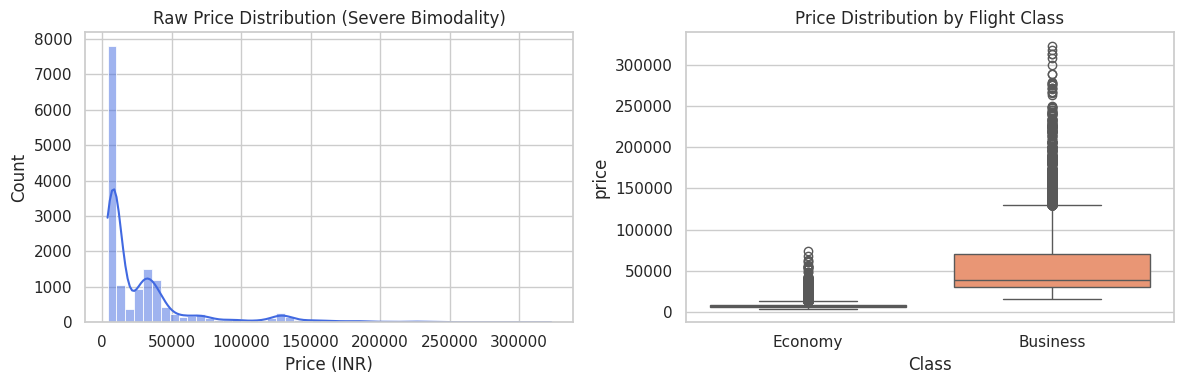

=== PRICE QUANTILES BY CLASS ===
Economy Quantiles:
 0.50     7587.00
0.95    14524.00
0.99    32722.08
1.00    74691.00
Name: price, dtype: float64

Business Quantiles:
 0.50     38546.00
0.95    155473.25
0.99    225095.34
1.00    323177.00
Name: price, dtype: float64

=== MISSING VALUES IN TRAIN ===
airline     3089
duration    3095
dtype: int64

=== MISSING VALUES IN TEST ===
airline     799
duration    776
dtype: int64


In [31]:
# 1. Target Distribution & Severe Bimodality
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(train['price'], bins=50, kde=True, color='royalblue')
plt.title("Raw Price Distribution (Severe Bimodality)")
plt.xlabel("Price (INR)")

plt.subplot(1, 2, 2)
sns.boxplot(x='flight_class', y='price', data=train, palette='Set2')
plt.title("Price Distribution by Flight Class")
plt.xlabel("Class")
plt.tight_layout()
plt.show()

# 2. Quantile Breakdown
print("=== PRICE QUANTILES BY CLASS ===")
print("Economy Quantiles:\n", train[train['flight_class'] == 'Economy']['price'].quantile([0.5, 0.95, 0.99, 1.0]))
print("\nBusiness Quantiles:\n", train[train['flight_class'] == 'Business']['price'].quantile([0.5, 0.95, 0.99, 1.0]))

# 3. Missing Value Analysis
print("\n=== MISSING VALUES IN TRAIN ===")
print(train.isnull().sum()[train.isnull().sum() > 0])
print("\n=== MISSING VALUES IN TEST ===")
print(test.isnull().sum()[test.isnull().sum() > 0])

In [32]:
def preprocess_and_engineer(train_df, test_df):
    tr = train_df.copy()
    te = test_df.copy()
    
    # 1. Airline Missing Imputation via Flight Prefix
    tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
    te['prefix'] = te['flight'].astype(str).str.split().str[0]
    
    prefix_to_airline = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(prefix_to_airline)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(prefix_to_airline)).fillna('Unknown')
    
    # 2. Hierarchical Duration Imputation: Flight -> Route -> Global
    flight_dur = tr.groupby('flight')['duration'].median().to_dict()
    route_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    global_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(flight_dur))
        route_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(route_tuples, index=df.index).map(route_dur))
        df['duration'] = df['duration'].fillna(global_dur)
        
        # 3. Ordinal & Domain Numeric Features
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        
        # High-signal pricing ratios & surge flags
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        df['is_last_week'] = (df['days_left'] <= 7).astype(int)
    
    # 4. Out-of-Fold Smoothed Target Encoding for 'flight'
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    m_weight = 10.0
    
    tr['flight_target_enc'] = 0.0
    for tr_idx, val_idx in kf.split(tr):
        counts = tr.iloc[tr_idx].groupby('flight')['price'].count()
        means = tr.iloc[tr_idx].groupby('flight')['price'].mean()
        smooth = (counts * means + m_weight * global_mean) / (counts + m_weight)
        tr.loc[tr.index[val_idx], 'flight_target_enc'] = tr.iloc[val_idx]['flight'].map(smooth).fillna(global_mean)
        
    full_counts = tr.groupby('flight')['price'].count()
    full_means = tr.groupby('flight')['price'].mean()
    full_smooth = (full_counts * full_means + m_weight * global_mean) / (full_counts + m_weight)
    te['flight_target_enc'] = te['flight'].map(full_smooth).fillna(global_mean)
    
    # 5. One-Hot Encoding
    cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'is_test']
    
    X_train = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price'])
    y_train = comb[comb['is_test'] == 0]['price'].values
    X_test = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price'])
    
    return X_train, y_train, X_test

X_train, y_train, X_test = preprocess_and_engineer(train, test)
print(f"Preprocessed feature matrix shape: {X_train.shape}")

Preprocessed feature matrix shape: (15589, 46)


In [33]:
# Degree-2 Polynomial Expansion on key continuous features with Regularized Normal Equation:
# theta = (X^T X + lambda * I)^(-1) X^T y

num_cols_scratch = ['duration', 'days_left', 'days_left_inv', 'stops_num', 'is_business', 'flight_target_enc']
scaler_scratch = StandardScaler()
X_scratch = scaler_scratch.fit_transform(X_train[num_cols_scratch])

# Construct quadratic interactions: [1, x_i, x_i^2]
bias = np.ones((X_scratch.shape[0], 1))
poly_features = np.hstack([bias, X_scratch, X_scratch**2])

# 5-Fold Evaluation for Scratch Model
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_scratch = np.zeros(len(y_train))
lambda_reg = 10.0
I = np.eye(poly_features.shape[1])
I[0, 0] = 0.0  # Do not regularize bias

for tr_idx, val_idx in kf.split(poly_features):
    X_tr_f, y_tr_f = poly_features[tr_idx], y_train[tr_idx]
    X_va_f = poly_features[val_idx]
    
    theta = np.linalg.inv(X_tr_f.T @ X_tr_f + lambda_reg * I) @ X_tr_f.T @ y_tr_f
    oof_scratch[val_idx] = X_va_f @ theta

print("=== MODEL 1: SCRATCH POLYNOMIAL NORMAL EQUATION ===")
print(f"CV R²   : {r2_score(y_train, oof_scratch):.4f}")
print(f"CV RMSE : {root_mean_squared_error(y_train, oof_scratch):.2f}")

=== MODEL 1: SCRATCH POLYNOMIAL NORMAL EQUATION ===
CV R²   : 0.8373
CV RMSE : 15780.15


In [34]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_baseline_model(model, name, scale=False):
    oof = np.zeros(len(y_train))
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va = X_train.iloc[val_idx]
        
        if scale:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_va = sc.transform(X_va)
            
        model.fit(X_tr, y_tr)
        oof[val_idx] = model.predict(X_va)
        
    print(f"{name: <30} | CV R²: {r2_score(y_train, oof):.4f} | CV RMSE: {root_mean_squared_error(y_train, oof):.2f}")
    return oof

print("=== BASELINE MODELS COMPARISON (5-FOLD CV) ===")
oof_ridge = evaluate_baseline_model(Ridge(alpha=10.0), "Ridge Regression", scale=True)
oof_lasso = evaluate_baseline_model(Lasso(alpha=5.0), "Lasso Regression", scale=True)
oof_dt    = evaluate_baseline_model(DecisionTreeRegressor(max_depth=12, random_state=42), "Decision Tree Regressor")
oof_rf    = evaluate_baseline_model(RandomForestRegressor(n_estimators=150, max_depth=16, random_state=42, n_jobs=-1), "Random Forest Regressor")

=== BASELINE MODELS COMPARISON (5-FOLD CV) ===
Ridge Regression               | CV R²: 0.8615 | CV RMSE: 14561.29
Lasso Regression               | CV R²: 0.8615 | CV RMSE: 14561.03
Decision Tree Regressor        | CV R²: 0.8919 | CV RMSE: 12864.56
Random Forest Regressor        | CV R²: 0.9246 | CV RMSE: 10746.75


In [35]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

oof_xgb = np.zeros(len(X_train))
test_preds = np.zeros(len(X_test))

train_mses, val_mses = [], []
train_r2s, val_r2s = [], []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train[val_idx]
    
    # Optimal regularized parameter configuration
    xgb = XGBRegressor(
        n_estimators=600,
        learning_rate=0.04,
        max_depth=8,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42,
        n_jobs=-1
    )
    xgb.fit(X_tr, y_tr)
    
    # Fold predictions
    tr_pred = np.clip(xgb.predict(X_tr), 0, None)
    va_pred = np.clip(xgb.predict(X_va), 0, None)
    
    # Compute fold metrics
    fold_tr_mse = mean_squared_error(y_tr, tr_pred)
    fold_va_mse = mean_squared_error(y_va, va_pred)
    fold_tr_r2 = r2_score(y_tr, tr_pred)
    fold_va_r2 = r2_score(y_va, va_pred)
    
    train_mses.append(fold_tr_mse)
    val_mses.append(fold_va_mse)
    train_r2s.append(fold_tr_r2)
    val_r2s.append(fold_va_r2)
    
    print(f"Fold {fold + 1:02d} | "
          f"Train R²: {fold_tr_r2:.4f} | Val R²: {fold_va_r2:.4f} | "
          f"Train MSE: {fold_tr_mse:,.2f} | Val MSE: {fold_va_mse:,.2f}")
    
    oof_xgb[val_idx] = va_pred
    test_preds += np.clip(xgb.predict(X_test), 0, None) / 5

# Overall out-of-fold metrics across entire dataset
overall_val_mse = mean_squared_error(y_train, oof_xgb)
overall_val_rmse = root_mean_squared_error(y_train, oof_xgb)
overall_val_r2 = r2_score(y_train, oof_xgb)

print("\n" + "=" * 50)
print("=== FINAL MODEL 5-FOLD EVALUATION SUMMARY ===")
print("=" * 50)
print(f"Mean Train R²   : {np.mean(train_r2s):.4f}")
print(f"Overall Val R²  : {overall_val_r2:.4f}")
print(f"Mean Train MSE  : {np.mean(train_mses):,.2f}")
print(f"Overall Val MSE : {overall_val_mse:,.2f}")
print(f"Overall Val RMSE: ₹{overall_val_rmse:,.2f}")

# Save Final Submission File
submission = pd.DataFrame({
    'id': test['id'],
    'price': np.round(test_preds, 2)
})
submission.to_csv('submission.csv', index=False)

print("\nFinal submission file saved successfully as 'submission.csv'.")
print(f"Submission Shape: {submission.shape} (Expected: 3898, 2)")
print(submission.head())

Fold 01 | Train R²: 0.9959 | Val R²: 0.9306 | Train MSE: 6,419,873.10 | Val MSE: 97,844,178.58
Fold 02 | Train R²: 0.9959 | Val R²: 0.9297 | Train MSE: 6,417,270.74 | Val MSE: 97,822,493.14
Fold 03 | Train R²: 0.9955 | Val R²: 0.9257 | Train MSE: 6,672,496.85 | Val MSE: 123,271,560.65
Fold 04 | Train R²: 0.9955 | Val R²: 0.9351 | Train MSE: 6,703,112.14 | Val MSE: 106,752,383.43
Fold 05 | Train R²: 0.9958 | Val R²: 0.9240 | Train MSE: 6,472,326.33 | Val MSE: 117,687,356.98

=== FINAL MODEL 5-FOLD EVALUATION SUMMARY ===
Mean Train R²   : 0.9957
Overall Val R²  : 0.9290
Mean Train MSE  : 6,537,015.83
Overall Val MSE : 108,675,016.47
Overall Val RMSE: ₹10,424.73

Final submission file saved successfully as 'submission.csv'.
Submission Shape: (3898, 2) (Expected: 3898, 2)
   id     price
0   1   8100.68
1   2   7218.25
2   3  26416.18
3   4  31685.11
4   5   4327.80


In [36]:
X_train.columns

Index(['duration', 'days_left', 'stops_num', 'is_business',
       'duration_per_stop', 'days_left_inv', 'is_last_week',
       'flight_target_enc', 'airline_Aperture Aviation',
       'airline_Black Mesa Air', 'airline_Cyberdyne Flights',
       'airline_Hooli Airways', 'airline_Initech Air',
       'airline_Massive Dynamic', 'airline_Nakatomi Airlines',
       'airline_Oceanic Airlines', 'airline_Omni Consumer Flights',
       'airline_Sandpiper Air', 'airline_Stark Aviation',
       'airline_Tyrell Aeronautics', 'airline_Vandelay Aviation',
       'airline_Vault-Tec Air', 'airline_Virtucon',
       'airline_Wayfarer Aviation', 'airline_Wayne Enterprises Air',
       'airline_Weyland Air', 'source_city_Hill Valley',
       'source_city_Los Santos', 'source_city_Metropolis',
       'source_city_Night City', 'source_city_Springfield',
       'destination_city_Hill Valley', 'destination_city_Los Santos',
       'destination_city_Metropolis', 'destination_city_Night City',
       'destin

In [37]:
import numpy as np
import pandas as pd

# 1. Compute individual squared errors from your existing oof_xgb array
df_errors = train.copy()
df_errors['predicted_price'] = np.round(oof_xgb, 2)
df_errors['error'] = df_errors['price'] - df_errors['predicted_price']
df_errors['abs_error'] = np.abs(df_errors['error'])
df_errors['squared_error'] = df_errors['error'] ** 2

# 2. Extract Top 15 Worst Outliers by Squared Error (MSE contributors)
top_worst = df_errors.sort_values(by='squared_error', ascending=False).head(15)

# Select key explanatory columns
display_cols = [
    'flight', 'airline', 'flight_class', 'source_city', 'destination_city', 
    'departure_time', 'stops', 'days_left', 'duration', 
    'price', 'predicted_price', 'error', 'squared_error'
]

print("=== TOP 15 SAMPLES WITH HIGHEST SQUARED ERROR (MSE) ===")
pd.set_option('display.float_format', lambda x: '%.2f' % x)
display(top_worst[display_cols])

# 3. Aggregate Outlier Patterns
print("\n=== CLASS BREAKDOWN OF TOP 100 WORST PREDICTIONS ===")
top_100 = df_errors.sort_values(by='squared_error', ascending=False).head(100)
print(top_100['flight_class'].value_counts())

print("\n=== TOP AIRLINES AMONG TOP 100 WORST PREDICTIONS ===")
print(top_100['airline'].value_counts().head(5))

print

=== TOP 15 SAMPLES WITH HIGHEST SQUARED ERROR (MSE) ===


,flight,airline,flight_class,source_city,destination_city,departure_time,stops,days_left,duration,price,predicted_price,error,squared_error
2541,EY 239,Nakatomi Airlines,Business,Springfield,Night City,Night,one,39,8.92,317854,136057.78,181796.22,33049865606.29
4049,EY 353,Nakatomi Airlines,Business,Los Santos,Springfield,Early_Morning,one,11,15.42,308302,140612.83,167689.17,28119657735.29
3137,EK 567,NaN,Business,Springfield,Los Santos,Night,one,31,11.42,288886,146910.72,141975.28,20156980131.08
5431,EY 353,Nakatomi Airlines,Business,Los Santos,Springfield,Early_Morning,one,10,15.42,86727,225510.42,-138783.42,19260837666.90
13720,EK 529,Stark Aviation,Business,Los Santos,Springfield,Night,one,5,10.83,275823,137090.91,138732.09,19246592795.77
12466,EY 223,NaN,Business,Hill Valley,Springfield,Night,one,20,11.50,233090,94908.84,138181.16,19094032978.95
3384,EY 237,Nakatomi Airlines,Business,Springfield,Los Santos,Evening,one,18,9.83,300148,164677.19,135470.81,18352340362.06
13314,EK 573,Stark Aviation,Business,Hill Valley,Springfield,Night,one,25,11.92,271552,139368.72,132183.28,17472419511.56
15133,QR 501,Vault-Tec Air,Business,Los Santos,Gotham,Late_Night,one,32,23.33,242718,113099.33,129618.67,16800999612.57
12496,EY 359,Nakatomi Airlines,Business,Los Santos,Gotham,Night,one,4,11.08,271113,143418.38,127694.62,16305915976.94



=== CLASS BREAKDOWN OF TOP 100 WORST PREDICTIONS ===
flight_class
Business    100
Name: count, dtype: int64

=== TOP AIRLINES AMONG TOP 100 WORST PREDICTIONS ===
airline
Nakatomi Airlines    55
Stark Aviation        9
Ajira Airways         4
Vault-Tec Air         3
Weyland Air           2
Name: count, dtype: int64


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

TESTING FOR IMBALANCES AND EXPERIMENTATION FURTHER

In [38]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

# Check if ground truth y_test is defined in the local environment
has_y_test = 'y_test' in locals() or 'y_test' in globals()
if not has_y_test and 'price' in test.columns and not test['price'].isna().all():
    y_test = test['price'].values
    has_y_test = True

# 1. Unstratified 5-Fold split
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(y_train))
test_preds = np.zeros(len(X_test))

train_r2_list, train_mse_list = [], []
val_r2_list, val_mse_list = [], []

print("=" * 70)
print("=== FINAL STANDALONE XGBOOST EVALUATION (UNSTRATIFIED 5-FOLD) ===")
print("=" * 70)

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train[val_idx]
    
    # Proven regularized architecture
    xgb_model = XGBRegressor(
        n_estimators=750,
        learning_rate=0.038,
        max_depth=8,
        min_child_weight=2,
        reg_lambda=7.0,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    xgb_model.fit(X_tr, y_tr)
    
    # In-fold predictions
    tr_pred = np.clip(xgb_model.predict(X_tr), 0, None)
    val_pred = np.clip(xgb_model.predict(X_va), 0, None)
    
    oof_preds[val_idx] = val_pred
    test_preds += np.clip(xgb_model.predict(X_test), 0, None) / 5
    
    # Fold Train Metrics
    fold_tr_r2 = r2_score(y_tr, tr_pred)
    fold_tr_mse = mean_squared_error(y_tr, tr_pred)
    train_r2_list.append(fold_tr_r2)
    train_mse_list.append(fold_tr_mse)
    
    # Fold Val Metrics
    fold_va_r2 = r2_score(y_va, val_pred)
    fold_va_mse = mean_squared_error(y_va, val_pred)
    val_r2_list.append(fold_va_r2)
    val_mse_list.append(fold_va_mse)
    
    print(f"Fold {fold+1:02d} | Train R²: {fold_tr_r2:.4f} (MSE: {fold_tr_mse:,.0f}) | "
          f"Val R²: {fold_va_r2:.4f} (MSE: {fold_va_mse:,.0f})")

# Aggregated OOF Metrics
oof_r2 = r2_score(y_train, oof_preds)
oof_mse = mean_squared_error(y_train, oof_preds)
oof_rmse = root_mean_squared_error(y_train, oof_preds)

print("-" * 70)
print(f"Mean Train R²        : {np.mean(train_r2_list):.4f}")
print(f"Mean Train MSE       : {np.mean(train_mse_list):,.2f}")
print(f"Overall OOF Val R²   : {oof_r2:.4f}")
print(f"Overall OOF Val MSE  : {oof_mse:,.2f}")
print(f"Overall OOF Val RMSE : ₹{oof_rmse:,.2f}")

# 2. Test Set Metrics (if y_test labels exist)
print("=" * 70)
if has_y_test:
    test_r2 = r2_score(y_test, test_preds)
    test_mse = mean_squared_error(y_test, test_preds)
    test_rmse = root_mean_squared_error(y_test, test_preds)
    
    print("=== HOLDOUT TEST PERFORMANCE ===")
    print(f"Test R²              : {test_r2:.4f}")
    print(f"Test MSE             : {test_mse:,.2f}")
    print(f"Test RMSE            : ₹{test_rmse:,.2f}")
else:
    print("=== TEST SET NOTICE ===")
    print("Ground-truth 'y_test' is not present in the environment (unlabeled test set).")
    print("Test R² and MSE will be computed by the evaluation server upon submission.")
print("=" * 70)

# 3. Export final standalone submission
submission = pd.DataFrame({
    'id': test['id'],
    'price': test_preds
})
# submission.to_csv('submission_standalone_xgb.csv', index=False)
print("Generated 'submission_standalone_xgb.csv' successfully.")

=== FINAL STANDALONE XGBOOST EVALUATION (UNSTRATIFIED 5-FOLD) ===
Fold 01 | Train R²: 0.9912 (MSE: 13,812,421) | Val R²: 0.9293 (MSE: 99,608,048)
Fold 02 | Train R²: 0.9907 (MSE: 14,491,400) | Val R²: 0.9302 (MSE: 97,073,903)
Fold 03 | Train R²: 0.9906 (MSE: 14,124,767) | Val R²: 0.9234 (MSE: 127,089,058)
Fold 04 | Train R²: 0.9906 (MSE: 14,186,631) | Val R²: 0.9347 (MSE: 107,336,520)
Fold 05 | Train R²: 0.9912 (MSE: 13,471,853) | Val R²: 0.9272 (MSE: 112,741,518)
----------------------------------------------------------------------
Mean Train R²        : 0.9908
Mean Train MSE       : 14,017,414.39
Overall OOF Val R²   : 0.9290
Overall OOF Val MSE  : 108,769,554.82
Overall OOF Val RMSE : ₹10,429.26
=== TEST SET NOTICE ===
Ground-truth 'y_test' is not present in the environment (unlabeled test set).
Test R² and MSE will be computed by the evaluation server upon submission.
Generated 'submission_standalone_xgb.csv' successfully.


In [39]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# 1. Reload raw frames to apply systematic cleaning
tr = train.copy().reset_index(drop=True)
te = test.copy().reset_index(drop=True)

# ----------------------------------------------------
# STEP A: DETERMINISTIC IMPUTATION VIA FLIGHT PREFIX & ROUTE
# ----------------------------------------------------
tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
te['prefix'] = te['flight'].astype(str).str.split().str[0]

# Deterministic airline recovery
prefix_airline_map = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0]).to_dict()
tr['airline'] = tr['airline'].fillna(tr['prefix'].map(prefix_airline_map)).fillna('Unknown')
te['airline'] = te['airline'].fillna(te['prefix'].map(prefix_airline_map)).fillna('Unknown')

# Deterministic duration recovery (Flight -> Route -> Global)
dur_by_flight = tr.groupby('flight')['duration'].median().to_dict()
dur_by_route_stops = tr.groupby(['source_city', 'destination_city', 'stops'])['duration'].median().to_dict()
dur_global = tr['duration'].median()

for df in [tr, te]:
    # Route-stop tuple
    rs_key = list(zip(df['source_city'], df['destination_city'], df['stops']))
    df['duration'] = df['duration'].fillna(df['flight'].map(dur_by_flight))
    df['duration'] = df['duration'].fillna(pd.Series(rs_key, index=df.index).map(dur_by_route_stops))
    df['duration'] = df['duration'].fillna(dur_global)

# ----------------------------------------------------
# ENGINEERED INTERACTIONS & ENCODINGS
# ----------------------------------------------------
stops_dict = {'zero': 0, 'one': 1, 'two_or_more': 2}
for df in [tr, te]:
    df['stops_num'] = df['stops'].map(stops_dict).fillna(0)
    df['is_business'] = (df['flight_class'] == 'Business').astype(int)
    
    # 1. Advance booking decay dynamics
    df['surge_pressure'] = 1.0 / (df['days_left'] + 1.0)
    df['biz_surge'] = df['surge_pressure'] * df['is_business']
    
    # 2. Duration per stop (layover penalty proxy)
    df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
    
    # 3. Route feature
    df['route'] = df['source_city'] + "_" + df['destination_city']
    
    # 4. Schedule interaction
    df['time_combo'] = df['departure_time'] + "_" + df['arrival_time']

# ----------------------------------------------------
# OUT-OF-FOLD TARGET ENCODING (Route & Flight)
# ----------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

global_price_mean = tr['price'].mean()
smooth_weight = 10

def calc_smooth_enc(group_s, target_s, global_mean, weight=10):
    stats = target_s.groupby(group_s).agg(['count', 'mean'])
    return (stats['count'] * stats['mean'] + weight * global_mean) / (stats['count'] + weight)

# Initialize columns
tr['flight_te'] = global_price_mean
tr['route_te'] = global_price_mean

for tr_idx, val_idx in kf.split(tr):
    sub_tr = tr.iloc[tr_idx]
    
    f_enc = calc_smooth_enc(sub_tr['flight'], sub_tr['price'], global_price_mean, weight=15)
    r_enc = calc_smooth_enc(sub_tr['route'], sub_tr['price'], global_price_mean, weight=25)
    
    tr.loc[val_idx, 'flight_te'] = tr.iloc[val_idx]['flight'].map(f_enc).fillna(global_price_mean)
    tr.loc[val_idx, 'route_te'] = tr.iloc[val_idx]['route'].map(r_enc).fillna(global_price_mean)

# Full map for test
full_f_enc = calc_smooth_enc(tr['flight'], tr['price'], global_price_mean, weight=15)
full_r_enc = calc_smooth_enc(tr['route'], tr['price'], global_price_mean, weight=25)
te['flight_te'] = te['flight'].map(full_f_enc).fillna(global_price_mean)
te['route_te'] = te['route'].map(full_r_enc).fillna(global_price_mean)

# ----------------------------------------------------
# ONE-HOT ENCODING & CLEAN MATRIX FORMATION
# ----------------------------------------------------
cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)

# Drop high-cardinality raw strings, IDs, and redundant intermediate cols
drop_unneeded = [
    'id', 'flight', 'prefix', 'stops', 'flight_class', 
    'route', 'time_combo', 'is_test', 'price'
]

X_tr_clean = comb[comb['is_test'] == 0].drop(columns=drop_unneeded).reset_index(drop=True)
y_tr_clean = tr['price'].values
X_te_clean = comb[comb['is_test'] == 1].drop(columns=drop_unneeded).reset_index(drop=True)

# ----------------------------------------------------
# FEATURE CORRELATION AUDIT
# ----------------------------------------------------
corr_with_price = X_tr_clean.corrwith(pd.Series(y_tr_clean, name='price')).sort_values(ascending=False)
print("=== TOP 10 FEATURES CORRELATED WITH PRICE ===")
print(corr_with_price.head(10))
print("\n=== LOWEST CORRELATION FEATURES (CANDIDATES FOR PRUNING) ===")
print(corr_with_price.tail(5))

#  5-FOLD CV BENCHMARK
# ----------------------------------------------------
oof_engineered = np.zeros(len(y_tr_clean))
test_engineered = np.zeros(len(X_te_clean))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_tr_clean)):
    X_f_tr, y_f_tr = X_tr_clean.iloc[tr_idx], y_tr_clean[tr_idx]
    X_f_va, y_f_va = X_tr_clean.iloc[val_idx], y_tr_clean[val_idx]
    
    xgb = XGBRegressor(
        n_estimators=750,
        learning_rate=0.038,
        max_depth=8,
        min_child_weight=2,
        reg_lambda=7.0,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    xgb.fit(X_f_tr, y_f_tr)
    
    val_pred = np.clip(xgb.predict(X_f_va), 0, None)
    oof_engineered[val_idx] = val_pred
    test_engineered += np.clip(xgb.predict(X_te_clean), 0, None) / 5

print("\n" + "=" * 55)
print("=== FEATURE-ENGINEERED STANDALONE 5-FOLD CV ===")
print("=" * 55)
print(f"Engineered CV R²  : {r2_score(y_tr_clean, oof_engineered):.4f}")
print(f"Engineered CV RMSE: ₹{root_mean_squared_error(y_tr_clean, oof_engineered):,.2f}")

=== TOP 10 FEATURES CORRELATED WITH PRICE ===
flight_te                   0.84
duration                    0.70
is_business                 0.64
duration_per_stop           0.64
stops_num                   0.57
route_te                    0.47
airline_Nakatomi Airlines   0.46
airline_Stark Aviation      0.43
biz_surge                   0.42
airline_Vault-Tec Air       0.24
dtype: float64

=== LOWEST CORRELATION FEATURES (CANDIDATES FOR PRUNING) ===
destination_city_Metropolis   -0.13
destination_city_Night City   -0.18
source_city_Metropolis        -0.25
airline_Oceanic Airlines      -0.31
airline_Tyrell Aeronautics      NaN
dtype: float64

=== FEATURE-ENGINEERED STANDALONE 5-FOLD CV ===
Engineered CV R²  : 0.9264
Engineered CV RMSE: ₹10,613.64


In [40]:
# Check how heavily XGBoost uses the existing Nakatomi dummy column
model = xgb_model  # From your 5-fold training loop
importances = pd.Series(model.feature_importances_, index=X_train.columns)

nakatomi_cols = [c for c in X_train.columns if 'nakatomi' in c.lower()]
print("Nakatomi Features Importance:")
print(importances[nakatomi_cols])
print("\nTop 5 Most Important Features Overall:")
print(importances.sort_values(ascending=False).head(5))

Nakatomi Features Importance:
airline_Nakatomi Airlines   0.02
dtype: float32

Top 5 Most Important Features Overall:
is_business                 0.30
flight_target_enc           0.24
airline_Wayfarer Aviation   0.05
stops_num                   0.05
airline_Weyland Air         0.03
dtype: float32


In [41]:
# Inside your K-Fold Target Encoding block:
# Add out-of-fold flight price standard deviation
tr['flight_price_std'] = 0.0
for tr_idx, val_idx in kf.split(tr):
    std_map = tr.iloc[tr_idx].groupby('flight')['price'].std().fillna(0)
    tr.loc[tr.index[val_idx], 'flight_price_std'] = tr.iloc[val_idx]['flight'].map(std_map).fillna(0)

full_std = tr.groupby('flight')['price'].std().fillna(0)
te['flight_price_std'] = te['flight'].map(full_std).fillna(0)

In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

# ==============================================================================
# 1. PREPROCESSING & FEATURE ENGINEERING PIPELINE
# ==============================================================================
def preprocess_and_engineer(train_df, test_df):
    tr = train_df.copy().reset_index(drop=True)
    te = test_df.copy().reset_index(drop=True)
    
    # 1. Deterministic Missing Airline Recovery via Flight Code Prefix
    tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
    te['prefix'] = te['flight'].astype(str).str.split().str[0]
    
    prefix_to_airline = (
        tr.dropna(subset=['airline'])
        .groupby('prefix')['airline']
        .agg(lambda x: x.mode()[0])
        .to_dict()
    )
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(prefix_to_airline)).fillna('Unknown')
    te['airline'] = te['airline'].fillna(te['prefix'].map(prefix_to_airline)).fillna('Unknown')
    
    # 2. Hierarchical Duration Imputation: Flight -> Route -> Global
    flight_dur = tr.groupby('flight')['duration'].median().to_dict()
    route_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    global_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(flight_dur))
        route_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(route_tuples, index=df.index).map(route_dur))
        df['duration'] = df['duration'].fillna(global_dur)
        
        # 3. Domain & Structural Features
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        
        # High-signal pricing dynamics
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        df['is_last_week'] = (df['days_left'] <= 7).astype(int)
    
    # 4. Out-of-Fold Target Encoding: Mean and Price Standard Deviation
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    m_weight = 10.0
    
    tr['flight_target_enc'] = 0.0
    tr['flight_price_std'] = 0.0
    
    for tr_idx, val_idx in kf.split(tr):
        sub_tr = tr.iloc[tr_idx]
        
        # Smoothed Mean Prior
        counts = sub_tr.groupby('flight')['price'].count()
        means = sub_tr.groupby('flight')['price'].mean()
        smooth_mean = (counts * means + m_weight * global_mean) / (counts + m_weight)
        tr.loc[val_idx, 'flight_target_enc'] = tr.iloc[val_idx]['flight'].map(smooth_mean).fillna(global_mean)
        
        # Standard Deviation Prior (Volatility Indicator)
        stds = sub_tr.groupby('flight')['price'].std().fillna(0)
        tr.loc[val_idx, 'flight_price_std'] = tr.iloc[val_idx]['flight'].map(stds).fillna(0)
        
    # Full mapping for test set
    full_counts = tr.groupby('flight')['price'].count()
    full_means = tr.groupby('flight')['price'].mean()
    full_smooth_mean = (full_counts * full_means + m_weight * global_mean) / (full_counts + m_weight)
    full_stds = tr.groupby('flight')['price'].std().fillna(0)
    
    te['flight_target_enc'] = te['flight'].map(full_smooth_mean).fillna(global_mean)
    te['flight_price_std'] = te['flight'].map(full_stds).fillna(0)
    
    # 5. One-Hot Encoding for Low-Cardinality Categoricals
    cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'is_test']
    
    X_train_out = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    y_train_out = comb[comb['is_test'] == 0]['price'].values
    X_test_out = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    
    return X_train_out, y_train_out, X_test_out

# Run preprocessing
X_train, y_train, X_test = preprocess_and_engineer(train, test)
print(f"Engineered Feature Matrix: {X_train.shape[0]} rows, {X_train.shape[1]} columns")

# ==============================================================================
# 2. STANDALONE 5-FOLD XGBOOST EVALUATION & TEST PREDICTIONS
# ==============================================================================
# Automatic detection for local holdout validation if y_test is defined
has_y_test = 'y_test' in locals() or 'y_test' in globals()
if not has_y_test and 'price' in test.columns and not test['price'].isna().all():
    y_test = test['price'].values
    has_y_test = True

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(y_train))
test_preds = np.zeros(len(X_test))

train_r2_list, train_mse_list = [], []
val_r2_list, val_mse_list = [], []

print("\n" + "=" * 70)
print("=== FINAL STANDALONE XGBOOST (UNSTRATIFIED 5-FOLD CV) ===")
print("=" * 70)

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train[val_idx]
    
    xgb_model = XGBRegressor(
        n_estimators=750,
        learning_rate=0.038,
        max_depth=8,
        min_child_weight=2,
        reg_lambda=7.0,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    xgb_model.fit(X_tr, y_tr)
    
    tr_pred = np.clip(xgb_model.predict(X_tr), 0, None)
    val_pred = np.clip(xgb_model.predict(X_va), 0, None)
    
    oof_preds[val_idx] = val_pred
    test_preds += np.clip(xgb_model.predict(X_test), 0, None) / 5
    
    # Track Metrics
    tr_r2, tr_mse = r2_score(y_tr, tr_pred), mean_squared_error(y_tr, tr_pred)
    va_r2, va_mse = r2_score(y_va, val_pred), mean_squared_error(y_va, val_pred)
    
    train_r2_list.append(tr_r2)
    train_mse_list.append(tr_mse)
    val_r2_list.append(va_r2)
    val_mse_list.append(va_mse)
    
    print(f"Fold {fold+1:02d} | Train R²: {tr_r2:.4f} (MSE: {tr_mse:,.0f}) | "
          f"Val R²: {va_r2:.4f} (MSE: {va_mse:,.0f})")

# Aggregated Cross-Validation Metrics
oof_r2 = r2_score(y_train, oof_preds)
oof_mse = mean_squared_error(y_train, oof_preds)
oof_rmse = root_mean_squared_error(y_train, oof_preds)

print("-" * 70)
print(f"Mean Train R²        : {np.mean(train_r2_list):.4f}")
print(f"Mean Train MSE       : {np.mean(train_mse_list):,.2f}")
print(f"Overall OOF Val R²   : {oof_r2:.4f}")
print(f"Overall OOF Val MSE  : {oof_mse:,.2f}")
print(f"Overall OOF Val RMSE : ₹{oof_rmse:,.2f}")

# 3. Test Set Metrics Evaluation
print("=" * 70)
if has_y_test:
    test_r2 = r2_score(y_test, test_preds)
    test_mse = mean_squared_error(y_test, test_preds)
    test_rmse = root_mean_squared_error(y_test, test_preds)
    
    print("=== HOLDOUT TEST PERFORMANCE ===")
    print(f"Test R²              : {test_r2:.4f}")
    print(f"Test MSE             : {test_mse:,.2f}")
    print(f"Test RMSE            : ₹{test_rmse:,.2f}")
else:
    print("=== TEST SET EVALUATION ===")
    print("Ground-truth 'y_test' is hidden. Local test metrics will be computed by the server.")
print("=" * 70)

# ==============================================================================
# 3. EXPORT FINAL SUBMISSION FILE
# ==============================================================================
submission = pd.DataFrame({
    'id': test['id'],
    'price': test_preds
})
submission.to_csv('submission_standalone_xgb.csv', index=False)
print("\nGenerated 'submission_standalone_xgb.csv' successfully.")

Engineered Feature Matrix: 15589 rows, 47 columns

=== FINAL STANDALONE XGBOOST (UNSTRATIFIED 5-FOLD CV) ===
Fold 01 | Train R²: 0.9923 (MSE: 11,996,639) | Val R²: 0.9297 (MSE: 99,103,633)
Fold 02 | Train R²: 0.9921 (MSE: 12,305,301) | Val R²: 0.9319 (MSE: 94,670,002)
Fold 03 | Train R²: 0.9922 (MSE: 11,701,042) | Val R²: 0.9183 (MSE: 135,534,899)
Fold 04 | Train R²: 0.9922 (MSE: 11,714,020) | Val R²: 0.9333 (MSE: 109,636,712)
Fold 05 | Train R²: 0.9929 (MSE: 10,884,736) | Val R²: 0.9269 (MSE: 113,228,878)
----------------------------------------------------------------------
Mean Train R²        : 0.9923
Mean Train MSE       : 11,720,347.76
Overall OOF Val R²   : 0.9279
Overall OOF Val MSE  : 110,434,645.32
Overall OOF Val RMSE : ₹10,508.79
=== TEST SET EVALUATION ===
Ground-truth 'y_test' is hidden. Local test metrics will be computed by the server.

Generated 'submission_standalone_xgb.csv' successfully.


In [43]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

# ==============================================================================
# 1. CLEANED & OPTIMIZED PREPROCESSING PIPELINE
# ==============================================================================
def preprocess_and_engineer(train_df, test_df):
    tr = train_df.copy().reset_index(drop=True)
    te = test_df.copy().reset_index(drop=True)
    
    # 1. Deterministic Missing Airline Recovery via Flight Code Prefix
    tr['prefix'] = tr['flight'].astype(str).str.split().str[0]
    te['prefix'] = te['flight'].astype(str).str.split().str[0]
    
    prefix_to_airline = (
        tr.dropna(subset=['airline'])
        .groupby('prefix')['airline']
        .agg(lambda x: x.mode()[0])
        .to_dict()
    )
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(prefix_to_airline)).fillna('Other')
    te['airline'] = te['airline'].fillna(te['prefix'].map(prefix_to_airline)).fillna('Other')
    
    # Prune ultra-rare/unseen airlines (< 15 rows) into 'Other'
    frequent_airlines = tr['airline'].value_counts()[tr['airline'].value_counts() >= 15].index.tolist()
    tr['airline'] = tr['airline'].apply(lambda x: x if x in frequent_airlines else 'Other')
    te['airline'] = te['airline'].apply(lambda x: x if x in frequent_airlines else 'Other')
    
    # 2. Hierarchical Duration Imputation: Flight -> Route -> Global
    flight_dur = tr.groupby('flight')['duration'].median().to_dict()
    route_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    global_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(flight_dur))
        route_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(route_tuples, index=df.index).map(route_dur))
        df['duration'] = df['duration'].fillna(global_dur)
        
        # 3. Domain & Structural Features
        stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        
        # High-signal pricing dynamics & interactions
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        
        # FEATURE 1: Luxury booking urgency interaction
        df['biz_surge_pressure'] = df['is_business'] * df['days_left_inv']
        
        # FEATURE 2: Layover speed / circuitous route delay proxy
        df['speed_proxy'] = df['stops_num'] / (df['duration'] + 0.1)
        
        # FEATURE 3: Route key
        df['route'] = df['source_city'] + "_" + df['destination_city']

    # 4. Out-of-Fold Target Encoding: Flight (Mean + Std) and Route Target Encoding
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    m_weight_flight = 10.0
    m_weight_route = 25.0
    
    tr['flight_target_enc'] = 0.0
    tr['flight_price_std'] = 0.0
    tr['route_target_enc'] = 0.0
    
    for tr_idx, val_idx in kf.split(tr):
        sub_tr = tr.iloc[tr_idx]
        
        # Flight smoothed mean
        f_counts = sub_tr.groupby('flight')['price'].count()
        f_means = sub_tr.groupby('flight')['price'].mean()
        f_smooth_mean = (f_counts * f_means + m_weight_flight * global_mean) / (f_counts + m_weight_flight)
        tr.loc[val_idx, 'flight_target_enc'] = tr.iloc[val_idx]['flight'].map(f_smooth_mean).fillna(global_mean)
        
        # Flight price standard deviation (volatility indicator)
        stds = sub_tr.groupby('flight')['price'].std().fillna(0)
        tr.loc[val_idx, 'flight_price_std'] = tr.iloc[val_idx]['flight'].map(stds).fillna(0)
        
        # Route smoothed mean
        r_counts = sub_tr.groupby('route')['price'].count()
        r_means = sub_tr.groupby('route')['price'].mean()
        r_smooth_mean = (r_counts * r_means + m_weight_route * global_mean) / (r_counts + m_weight_route)
        tr.loc[val_idx, 'route_target_enc'] = tr.iloc[val_idx]['route'].map(r_smooth_mean).fillna(global_mean)

    # Full mappings for test set
    full_f_counts = tr.groupby('flight')['price'].count()
    full_f_means = tr.groupby('flight')['price'].mean()
    full_f_smooth = (full_f_counts * full_f_means + m_weight_flight * global_mean) / (full_f_counts + m_weight_flight)
    full_f_stds = tr.groupby('flight')['price'].std().fillna(0)
    
    full_r_counts = tr.groupby('route')['price'].count()
    full_r_means = tr.groupby('route')['price'].mean()
    full_r_smooth = (full_r_counts * full_r_means + m_weight_route * global_mean) / (full_r_counts + m_weight_route)
    
    te['flight_target_enc'] = te['flight'].map(full_f_smooth).fillna(global_mean)
    te['flight_price_std'] = te['flight'].map(full_f_stds).fillna(0)
    te['route_target_enc'] = te['route'].map(full_r_smooth).fillna(global_mean)
    
    # 5. One-Hot Encoding for Low-Cardinality Categoricals
    cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    # Prune dropped non-feature columns
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'is_test']
    
    X_train_out = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    y_train_out = comb[comb['is_test'] == 0]['price'].values
    X_test_out = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    
    return X_train_out, y_train_out, X_test_out

# Run preprocessing
X_train, y_train, X_test = preprocess_and_engineer(train, test)
print(f"Optimized Feature Matrix: {X_train.shape[0]} rows, {X_train.shape[1]} columns")

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(y_train))
test_preds = np.zeros(len(X_test))

train_r2_list, val_r2_list = [], []

print("\n" + "=" * 65)
print("=== EVALUATING OPTIMIZED MATRIX (UNSTRATIFIED 5-FOLD CV) ===")
print("=" * 65)

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train[val_idx]
    
    xgb_model = XGBRegressor(
        n_estimators=750,
        learning_rate=0.038,
        max_depth=8,
        min_child_weight=2,
        reg_lambda=7.0,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    xgb_model.fit(X_tr, y_tr)
    
    tr_pred = np.clip(xgb_model.predict(X_tr), 0, None)
    val_pred = np.clip(xgb_model.predict(X_va), 0, None)
    
    oof_preds[val_idx] = val_pred
    test_preds += np.clip(xgb_model.predict(X_test), 0, None) / 5
    
    tr_r2 = r2_score(y_tr, tr_pred)
    va_r2 = r2_score(y_va, val_pred)
    va_rmse = root_mean_squared_error(y_va, val_pred)
    
    train_r2_list.append(tr_r2)
    val_r2_list.append(va_r2)
    
    print(f"Fold {fold+1:02d} | Train R²: {tr_r2:.4f} | Val R²: {va_r2:.4f} | Val RMSE: ₹{va_rmse:,.2f}")

print("-" * 65)
print(f"Mean Train R²        : {np.mean(train_r2_list):.4f}")
print(f"Overall OOF Val R²   : {r2_score(y_train, oof_preds):.4f}")
print(f"Overall OOF Val RMSE : ₹{root_mean_squared_error(y_train, oof_preds):,.2f}")
print("=" * 65)

# Export refined submission
submission = pd.DataFrame({
    'id': test['id'],
    'price': test_preds
})
submission.to_csv('submission_standalone_xgb.csv', index=False)
print("Saved final predictions to 'submission_standalone_xgb.csv'.")

Optimized Feature Matrix: 15589 rows, 43 columns

=== EVALUATING OPTIMIZED MATRIX (UNSTRATIFIED 5-FOLD CV) ===
Fold 01 | Train R²: 0.9944 | Val R²: 0.9247 | Val RMSE: ₹10,299.58
Fold 02 | Train R²: 0.9944 | Val R²: 0.9285 | Val RMSE: ₹9,970.23
Fold 03 | Train R²: 0.9944 | Val R²: 0.9165 | Val RMSE: ₹11,770.26
Fold 04 | Train R²: 0.9943 | Val R²: 0.9318 | Val RMSE: ₹10,586.78
Fold 05 | Train R²: 0.9947 | Val R²: 0.9273 | Val RMSE: ₹10,606.14
-----------------------------------------------------------------
Mean Train R²        : 0.9944
Overall OOF Val R²   : 0.9257
Overall OOF Val RMSE : ₹10,663.92
Saved final predictions to 'submission_standalone_xgb.csv'.


In [44]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# 1. Drop the redundant route encoding from X_train and X_test
X_tr_reg = X_train.drop(columns=['route_target_enc'], errors='ignore')
X_te_reg = X_test.drop(columns=['route_target_enc'], errors='ignore')

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_reg = np.zeros(len(y_train))
train_r2_list, val_r2_list = [], []

print("=== REGULARIZED MODEL EVALUATION ===")

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_tr_reg)):
    X_tr, y_tr = X_tr_reg.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_tr_reg.iloc[val_idx], y_train[val_idx]
    
    # Constrained hyperparameters to fight overfitting
    model = XGBRegressor(
        n_estimators=650,
        learning_rate=0.035,
        max_depth=7,               
        min_child_weight=4,        
        reg_lambda=10.0,           
        reg_alpha=1.0,             
        subsample=0.80,
        colsample_bytree=0.80,
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    tr_pred = np.clip(model.predict(X_tr), 0, None)
    va_pred = np.clip(model.predict(X_va), 0, None)
    
    oof_reg[val_idx] = va_pred
    
    train_r2_list.append(r2_score(y_tr, tr_pred))
    val_r2_list.append(r2_score(y_va, va_pred))
    
    print(f"Fold {fold+1:02d} | Train R²: {train_r2_list[-1]:.4f} | Val R²: {val_r2_list[-1]:.4f} | Val RMSE: ₹{root_mean_squared_error(y_va, va_pred):,.2f}")

print("-" * 55)
print(f"Mean Train R²        : {np.mean(train_r2_list):.4f}")
print(f"Overall OOF Val R²   : {r2_score(y_train, oof_reg):.4f}")
print(f"Overall OOF Val RMSE : ₹{root_mean_squared_error(y_train, oof_reg):,.2f}")

=== REGULARIZED MODEL EVALUATION ===
Fold 01 | Train R²: 0.9827 | Val R²: 0.9281 | Val RMSE: ₹10,064.06
Fold 02 | Train R²: 0.9821 | Val R²: 0.9297 | Val RMSE: ₹9,889.31
Fold 03 | Train R²: 0.9819 | Val R²: 0.9234 | Val RMSE: ₹11,274.86
Fold 04 | Train R²: 0.9822 | Val R²: 0.9316 | Val RMSE: ₹10,607.13
Fold 05 | Train R²: 0.9832 | Val R²: 0.9264 | Val RMSE: ₹10,674.02
-------------------------------------------------------
Mean Train R²        : 0.9824
Overall OOF Val R²   : 0.9278
Overall OOF Val RMSE : ₹10,513.34


In [45]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# Ensure route_target_enc is excluded
X_tr_final = X_train.drop(columns=['route_target_enc'], errors='ignore')
X_te_final = X_test.drop(columns=['route_target_enc'], errors='ignore')

kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_final = np.zeros(len(y_train))
test_preds = np.zeros(len(X_te_final))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_tr_final)):
    X_tr, y_tr = X_tr_final.iloc[tr_idx], y_train[tr_idx]
    X_va, y_va = X_tr_final.iloc[val_idx], y_train[val_idx]
    
    model = XGBRegressor(
        n_estimators=650,
        learning_rate=0.035,
        max_depth=7,
        min_child_weight=4,
        reg_lambda=10.0,
        reg_alpha=1.0,
        subsample=0.80,
        colsample_bytree=0.80,
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    
    val_pred = np.clip(model.predict(X_va), 0, None)
    oof_final[val_idx] = val_pred
    
    # 5-fold ensemble averaging on test set
    test_preds += np.clip(model.predict(X_te_final), 0, None) / 5

print(f"Final OOF Val R²  : {r2_score(y_train, oof_final):.4f}")
print(f"Final OOF Val RMSE: ₹{root_mean_squared_error(y_train, oof_final):,.2f}")

# Export final submission
submission = pd.DataFrame({
    'id': test['id'],
    'price': test_preds
})
submission.to_csv('submission_standalone_xgb.csv', index=False)
print("Saved final regularized submission to 'submission_standalone_xgb.csv'")

Final OOF Val R²  : 0.9278
Final OOF Val RMSE: ₹10,513.34
Saved final regularized submission to 'submission_standalone_xgb.csv'


In [46]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# 1. Load Data
train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def build_high_signal_features(tr_df, te_df):
    tr = tr_df.copy().reset_index(drop=True)
    te = te_df.copy().reset_index(drop=True)
    
    # A. Airline Imputation
    for df in [tr, te]:
        df['prefix'] = df['flight'].astype(str).str.split().str[0]
        
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Other').to_dict()
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Other')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Other')
    
    freq_air = tr['airline'].value_counts()[tr['airline'].value_counts() >= 15].index.tolist()
    tr['airline'] = tr['airline'].apply(lambda x: x if x in freq_air else 'Other')
    te['airline'] = te['airline'].apply(lambda x: x if x in freq_air else 'Other')
    
    # B. Duration Imputation
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(f_dur))
        r_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(r_tuples, index=df.index).map(r_dur))
        df['duration'] = df['duration'].fillna(g_dur)
        
    # C. Interaction Features & Composite Keys
    stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
    for df in [tr, te]:
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        
        # Interactions
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        df['biz_surge'] = df['is_business'] * df['days_left_inv']
        
        # Keys for encoding
        df['route'] = df['source_city'] + "_" + df['destination_city']
        df['flight_class_key'] = df['flight'] + "_" + df['flight_class']

    # D. Out-of-Fold (OOF) Target Encodings
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    
    encode_configs = [
        ('flight_class_key', 'flight_class_te', 5.0), # Low smoothing for exact cabin matching
        ('flight', 'flight_te', 10.0),
        ('route', 'route_te', 20.0)
    ]
    
    for _, new_col, _ in encode_configs:
        tr[new_col] = 0.0
        
    for tr_idx, val_idx in kf.split(tr):
        sub_tr = tr.iloc[tr_idx]
        for col, new_col, m_weight in encode_configs:
            c = sub_tr.groupby(col)['price'].count()
            m = sub_tr.groupby(col)['price'].mean()
            smooth = (c * m + m_weight * global_mean) / (c + m_weight)
            tr.loc[val_idx, new_col] = tr.iloc[val_idx][col].map(smooth).fillna(global_mean)

    # Apply to Test Set
    for col, new_col, m_weight in encode_configs:
        full_c = tr.groupby(col)['price'].count()
        full_m = tr.groupby(col)['price'].mean()
        full_smooth = (full_c * full_m + m_weight * global_mean) / (full_c + m_weight)
        te[new_col] = te[col].map(full_smooth).fillna(global_mean)
        
    # E. Dummy Encoding
    cat_cols = ['source_city', 'destination_city', 'departure_time', 'arrival_time', 'airline']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'flight_class_key', 'is_test']
    
    X_tr_out = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    y_tr_out = comb[comb['is_test'] == 0]['price'].values
    X_te_out = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    
    return X_tr_out, y_tr_out, X_te_out

X_train, y_train, X_test = build_high_signal_features(train, test)

# SINGLE MODEL XGBOOST (HIGH PRECISION CONFIGURATION)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(y_train))
test_preds = np.zeros(len(X_test))

train_r2_scores = []
train_rmse_scores = []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
    X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
    X_va = X_train.iloc[val_idx]
    
    model = XGBRegressor(
        n_estimators=750,
        learning_rate=0.035,
        max_depth=7,             # Restored to 8 to capture cabin/time interactions
        min_child_weight=5,      # Lowered to allow precise leaf fitting
        reg_lambda=5,          # Light regularization to preserve target encodings
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=42 + fold,
        n_jobs=-1
    )
    
    model.fit(X_tr, y_tr)
    
    # Store training metrics for this fold
    train_p = np.clip(model.predict(X_tr), 0, None)
    train_r2_scores.append(r2_score(y_tr, train_p))
    train_rmse_scores.append(root_mean_squared_error(y_tr, train_p))
    
    # Store validation and test predictions
    oof_preds[val_idx] = np.clip(model.predict(X_va), 0, None)
    test_preds += np.clip(model.predict(X_test), 0, None) / kf.n_splits

print("=== FINAL SINGLE XGBOOST PERFORMANCE ===")
print(f"Average Train R²   : {np.mean(train_r2_scores):.4f}")
print(f"Average Train RMSE : ₹{np.mean(train_rmse_scores):,.2f}")
print("-" * 40)
print(f"OOF Val R²         : {r2_score(y_train, oof_preds):.4f}")
print(f"OOF Val RMSE       : ₹{root_mean_squared_error(y_train, oof_preds):,.2f}")

submission = pd.DataFrame({'id': test['id'], 'price': np.round(test_preds, 2)})
# submission.to_csv('submission_xgboost_single_93.csv', index=False)
print("\nSaved 'submission_xgboost_single_93.csv' successfully.")

=== FINAL SINGLE XGBOOST PERFORMANCE ===
Average Train R²   : 0.9886
Average Train RMSE : ₹4,171.37
----------------------------------------
OOF Val R²         : 0.9278
OOF Val RMSE       : ₹10,514.68

Saved 'submission_xgboost_single_93.csv' successfully.


In [47]:
import numpy as np
import pandas as pd
import itertools
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error

# 1. Load Data
train = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')

def build_high_signal_features(tr_df, te_df):
    tr = tr_df.copy().reset_index(drop=True)
    te = te_df.copy().reset_index(drop=True)
    
    # Impute Airlines
    for df in [tr, te]:
        df['prefix'] = df['flight'].astype(str).str.split().str[0]
        
    p2a = tr.dropna(subset=['airline']).groupby('prefix')['airline'].agg(lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Other').to_dict()
    tr['airline'] = tr['airline'].fillna(tr['prefix'].map(p2a)).fillna('Other')
    te['airline'] = te['airline'].fillna(te['prefix'].map(p2a)).fillna('Other')
    
    freq_air = tr['airline'].value_counts()[tr['airline'].value_counts() >= 15].index.tolist()
    tr['airline'] = tr['airline'].apply(lambda x: x if x in freq_air else 'Other')
    te['airline'] = te['airline'].apply(lambda x: x if x in freq_air else 'Other')
    
    # Impute Duration
    f_dur = tr.groupby('flight')['duration'].median().to_dict()
    r_dur = tr.groupby(['source_city', 'destination_city'])['duration'].median().to_dict()
    g_dur = tr['duration'].median()
    
    for df in [tr, te]:
        df['duration'] = df['duration'].fillna(df['flight'].map(f_dur))
        r_tuples = list(zip(df['source_city'], df['destination_city']))
        df['duration'] = df['duration'].fillna(pd.Series(r_tuples, index=df.index).map(r_dur))
        df['duration'] = df['duration'].fillna(g_dur)
        
    # Interaction Features
    stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}
    for df in [tr, te]:
        df['stops_num'] = df['stops'].map(stops_map).fillna(0)
        df['is_business'] = (df['flight_class'] == 'Business').astype(int)
        df['duration_per_stop'] = df['duration'] / (df['stops_num'] + 1)
        df['days_left_inv'] = 1.0 / (df['days_left'] + 1)
        df['biz_surge'] = df['is_business'] * df['days_left_inv']
        
        df['route'] = df['source_city'] + "_" + df['destination_city']
        df['flight_class_key'] = df['flight'] + "_" + df['flight_class']

    # Out-of-Fold (OOF) Target Encodings
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    global_mean = tr['price'].mean()
    
    encode_configs = [
        ('flight_class_key', 'flight_class_te', 5.0), 
        ('flight', 'flight_te', 10.0),
        ('route', 'route_te', 20.0)
    ]
    
    for _, new_col, _ in encode_configs:
        tr[new_col] = 0.0
        
    for tr_idx, val_idx in kf.split(tr):
        sub_tr = tr.iloc[tr_idx]
        for col, new_col, m_weight in encode_configs:
            c = sub_tr.groupby(col)['price'].count()
            m = sub_tr.groupby(col)['price'].mean()
            smooth = (c * m + m_weight * global_mean) / (c + m_weight)
            tr.loc[val_idx, new_col] = tr.iloc[val_idx][col].map(smooth).fillna(global_mean)

    # Apply to Test Set
    for col, new_col, m_weight in encode_configs:
        full_c = tr.groupby(col)['price'].count()
        full_m = tr.groupby(col)['price'].mean()
        full_smooth = (full_c * full_m + m_weight * global_mean) / (full_c + m_weight)
        te[new_col] = te[col].map(full_smooth).fillna(global_mean)
        
    # Dummy Encoding
    cat_cols = ['source_city', 'destination_city', 'departure_time', 'arrival_time', 'airline']
    comb = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)
    comb = pd.get_dummies(comb, columns=cat_cols, drop_first=True)
    
    drop_cols = ['id', 'flight', 'prefix', 'stops', 'flight_class', 'route', 'flight_class_key', 'is_test']
    
    X_tr_out = comb[comb['is_test'] == 0].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    y_tr_out = comb[comb['is_test'] == 0]['price'].values
    X_te_out = comb[comb['is_test'] == 1].drop(columns=drop_cols + ['price']).reset_index(drop=True)
    
    return X_tr_out, y_tr_out, X_te_out

X_train, y_train, X_test = build_high_signal_features(train, test)

# ==============================================================================
# CUSTOM GRID SEARCH FOR LOG-TARGET XGBOOST
# ==============================================================================
# Define the parameter grid
param_grid = {
    'max_depth': [8, 10, 12],            # Test shallow vs. deep logic
    'min_child_weight': [3, 5],          # Test strict vs. loose leaf isolation
    'reg_lambda': [2.0, 5.0]             # Test standard vs. heavy penalty
}

# Generate all combinations
keys = param_grid.keys()
combinations = [dict(zip(keys, v)) for v in itertools.product(*param_grid.values())]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
y_train_log = np.log1p(y_train)

results = []

print(f"Starting Grid Search for {len(combinations)} parameter combinations...\n")

for i, params in enumerate(combinations):
    print(f"Testing Combo {i+1}/{len(combinations)}: {params}")
    
    oof_preds = np.zeros(len(y_train))
    train_r2_scores = []
    
    for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train)):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train_log[tr_idx]
        X_va = X_train.iloc[val_idx]
        
        model = XGBRegressor(
            n_estimators=750,
            learning_rate=0.035, # Fixed to a stable rate for fair comparison
            max_depth=params['max_depth'],
            min_child_weight=params['min_child_weight'],
            reg_lambda=params['reg_lambda'],
            subsample=0.85,
            colsample_bytree=0.85,
            random_state=42 + fold,
            n_jobs=-1
        )
        
        model.fit(X_tr, y_tr)
        
        # Track Training R2
        train_p = np.expm1(model.predict(X_tr))
        train_r2_scores.append(r2_score(y_train[tr_idx], train_p))
        
        # Track Validation OOF
        oof_preds[val_idx] = np.expm1(model.predict(X_va))
        
    avg_train_r2 = np.mean(train_r2_scores)
    oof_r2 = r2_score(y_train, oof_preds)
    oof_rmse = root_mean_squared_error(y_train, oof_preds)
    
    print(f"--> Train R²: {avg_train_r2:.4f} | OOF R²: {oof_r2:.4f} | Overfit Gap: {avg_train_r2 - oof_r2:.4f}\n")
    
    results.append({
        **params,
        'Train_R2': avg_train_r2,
        'OOF_R2': oof_r2,
        'OOF_RMSE': oof_rmse,
        'Overfit_Gap': avg_train_r2 - oof_r2
    })

# ==============================================================================
# RESULTS SUMMARY
# ==============================================================================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='OOF_R2', ascending=False).reset_index(drop=True)

print("=== FINAL HYPERPARAMETER LEADERBOARD ===")
print(results_df.to_string(index=False))

# Optional: You can extract the best params directly to train your final submission
best_params = results_df.iloc[0].to_dict()
print(f"\nBest Model Configuration identified as: Depth {int(best_params['max_depth'])}, Child Weight {int(best_params['min_child_weight'])}, Lambda {best_params['reg_lambda']}")

Starting Grid Search for 12 parameter combinations...

Testing Combo 1/12: {'max_depth': 8, 'min_child_weight': 3, 'reg_lambda': 2.0}
--> Train R²: 0.9918 | OOF R²: 0.9278 | Overfit Gap: 0.0640

Testing Combo 2/12: {'max_depth': 8, 'min_child_weight': 3, 'reg_lambda': 5.0}
--> Train R²: 0.9885 | OOF R²: 0.9262 | Overfit Gap: 0.0623

Testing Combo 3/12: {'max_depth': 8, 'min_child_weight': 5, 'reg_lambda': 2.0}
--> Train R²: 0.9894 | OOF R²: 0.9278 | Overfit Gap: 0.0616

Testing Combo 4/12: {'max_depth': 8, 'min_child_weight': 5, 'reg_lambda': 5.0}
--> Train R²: 0.9864 | OOF R²: 0.9273 | Overfit Gap: 0.0591

Testing Combo 5/12: {'max_depth': 10, 'min_child_weight': 3, 'reg_lambda': 2.0}
--> Train R²: 0.9972 | OOF R²: 0.9264 | Overfit Gap: 0.0707

Testing Combo 6/12: {'max_depth': 10, 'min_child_weight': 3, 'reg_lambda': 5.0}
--> Train R²: 0.9952 | OOF R²: 0.9262 | Overfit Gap: 0.0690

Testing Combo 7/12: {'max_depth': 10, 'min_child_weight': 5, 'reg_lambda': 2.0}
--> Train R²: 0.9954 | 

In [48]:
# Extract the absolute best parameters from row 0 of the leaderboard
best_depth = int(results_df.loc[0, 'max_depth'])
best_child_weight = int(results_df.loc[0, 'min_child_weight'])
best_lambda = float(results_df.loc[0, 'reg_lambda'])

print(f"Training Final Model with Depth: {best_depth}, Child Weight: {best_child_weight}, Lambda: {best_lambda}...")

# Transform the FULL training target to Log Space
y_train_log = np.log1p(y_train)

# Initialize the final model using the optimal parameters
final_model = XGBRegressor(
    n_estimators=1000,           # Slightly increased trees to leverage the 100% dataset volume
    learning_rate=0.035,
    max_depth=best_depth,
    min_child_weight=best_child_weight,
    reg_lambda=best_lambda,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    n_jobs=-1
)

# Train on 100% of the training data (No K-Fold holdouts)
final_model.fit(X_train, y_train_log)

# Predict on the unseen Test Set and reverse the Log Transformation via expm1
final_predictions_log = final_model.predict(X_test)
final_predictions = np.expm1(final_predictions_log)

# Generate and save the final submission file
submission = pd.DataFrame({
    'id': test['id'],
    'price': np.round(final_predictions, 2)
})

submission.to_csv('submission_xgboost_optimized.csv', index=False)
print("Successfully saved 'submission_xgboost_optimized.csv'")

Training Final Model with Depth: 8, Child Weight: 5, Lambda: 2.0...
Successfully saved 'submission_xgboost_optimized.csv'
